## **Import thư viện**

In [54]:
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import seaborn as sns
import plotly.express as px
import shap
import io
!pip install mrmr-selection
import mrmr
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from PIL import Image
from sklearn.cluster import KMeans
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import make_column_selector as selector
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, PowerTransformer, OneHotEncoder, RobustScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted
!pip install bayesian-optimization
from bayes_opt import BayesianOptimization

## **Build hàm lưu scatter plot**

In [ ]:
def save_scatter_plot(y_test, y_pred_test, scatter_plot_name=''):
    plt.figure(figsize=(8, 6))
    plt.scatter(y_test, y_pred_test, alpha=0.5)
    plt.xlabel("Actual pH")
    plt.ylabel("Predicted pH")
    plt.title(scatter_plot_name)
    plt.grid(True)
    # Add a diagonal line for perfect prediction
    min_val = min(y_test.min(), y_pred_test.min())
    max_val = max(y_test.max(), y_pred_test.max())
    plt.plot([min_val, max_val], [min_val, max_val], 'k--', lw=2)
    plt.savefig(f"{scatter_plot_name}.png", bbox_inches='tight')

## **Build hàm đánh giá model**

In [5]:
def metrics_calculation(model, X_train, y_train, X_test, y_test, bar_chart_name='', scatter_plot_name='', save_barchart: bool=False, save_plot: bool=False):
    """
    Calculate metrics, print results, plot bar chart of RMSE/R2, and plot scatter of Actual vs Predicted.
    """
    # 1. Calculate metrics
    y_pred_test = model.predict(X_test)
    rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
    r2_test = r2_score(y_test, y_pred_test)

    y_pred_train = model.predict(X_train)
    rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
    r2_train = r2_score(y_train, y_pred_train)

    print(f"--- {bar_chart_name} ---")
    print("Training RMSE:", round(rmse_train, 4))
    print("Testing RMSE:", round(rmse_test, 4))
    print("Training R²:", round(r2_train, 4))
    print("Testing R²:", round(r2_test, 4))

    # 2. Bar chart các metrics
    metrics = ['RMSE', 'R²']
    training_values = [rmse_train, r2_train]
    testing_values = [rmse_test, r2_test]

    x = np.arange(len(metrics))
    width = 0.35

    fig, ax = plt.subplots(figsize=(8, 5))
    rects1 = ax.bar(x - width/2, training_values, width, label='Training', color='skyblue')
    rects2 = ax.bar(x + width/2, testing_values, width, label='Testing', color='lightgreen')

    ax.set_ylabel('Value')
    ax.set_title(bar_chart_name)
    ax.set_xticks(x)
    ax.set_xticklabels(metrics)
    ax.legend()

    def autolabel(rects):
        for rect in rects:
            height = rect.get_height()
            ax.annotate(f'{height:.4f}',
                        xy=(rect.get_x() + rect.get_width() / 2, height),
                        xytext=(0, 3),
                        textcoords="offset points",
                        ha='center', va='bottom')

    autolabel(rects1)
    autolabel(rects2)
    fig.tight_layout()
    if (save_barchart):
      plt.savefig(f"{bar_chart_name}.png", bbox_inches='tight')
    plt.show()

    # 3. Scatter plot
    plt.figure(figsize=(8, 6))
    plt.scatter(y_test, y_pred_test, alpha=0.5)
    plt.xlabel("Actual pH")
    plt.ylabel("Predicted pH")
    plt.title(scatter_plot_name)
    plt.grid(True)
    # Add a diagonal line for perfect prediction
    min_val = min(y_test.min(), y_pred_test.min())
    max_val = max(y_test.max(), y_pred_test.max())
    plt.plot([min_val, max_val], [min_val, max_val], 'k--', lw=2)
    if (save_plot):
      plt.savefig(f"{scatter_plot_name}.png", bbox_inches='tight')
    plt.show()

## **Build hàm SHAP value**

In [ ]:
def calculate_and_plot_shap(model, X_train, X_test, feature_names, summary_title='', waterfall_title='', save_summary=0, save_waterfall=0):
    """
    Calculates and plots SHAP values for a given model.

    Args:
        model: The trained model with a .predict method.
        X_train (np.ndarray or pd.DataFrame): Preprocessed training data.
        X_test (np.ndarray or pd.DataFrame): Preprocessed testing data.
        feature_names (list or np.ndarray): Names of the features.
        summary_title: Name of the summary plot
        waterfall_title: Name of the waterfall plot
        save_summary: Save the summary plot or not
        save_waterfall: Save the waterfall plot or not
    """

    # 1. Tạo tập dữ liệu nền thu nhỏ (Background Data)
    # Sử dụng K-Means để lấy 50 điểm đại diện từ tập huấn luyện đã được tiền xử lý
    background_data = shap.kmeans(X_train, 50)

    # 2. Khởi tạo KernelExplainer với hàm predict của model
    explainer = shap.KernelExplainer(model.predict, background_data)

    # 3. Tính toán SHAP values cho toàn bộ mẫu trong tập test
    X_test_df = pd.DataFrame(X_test, columns=feature_names)
    shap_values = explainer.shap_values(X_test_df)

    # 4. Biểu diễn kết quả dạng Summary Plot
    shap.summary_plot(shap_values, X_test_df, feature_names=feature_names)
    if (save_summary):
        shap.summary_plot(shap_values, X_test_df, feature_names=feature_names, show=False)
        plt.savefig(
            f'{summary_title}.png',
            bbox_inches="tight"
        )


    # 5. Thêm Waterfall Plot cho một mẫu cụ thể (ví dụ: mẫu đầu tiên trong tập con)
    print("\n--- SHAP Waterfall Plot for the first test sample ---")
    shap.plots.waterfall(shap.Explanation(values=shap_values[0],
                                         base_values=explainer.expected_value,
                                         data=X_test_df.iloc[0],
                                         feature_names=feature_names))
    if (save_waterfall):
        shap.plots.waterfall(shap.Explanation(values=shap_values[0],
                                         base_values=explainer.expected_value,
                                         data=X_test_df.iloc[0],
                                         feature_names=feature_names), show=False)
        plt.savefig(
            f'{waterfall_title}.png',
            bbox_inches="tight"
        )

## **Build hàm biểu diễn phổ**

In [21]:
def spectra_plot(df, plot_name='', save_fig: bool=False):
    # Lưu tên tất cả các cột của df vào wavelengths
    wavelengths = df.columns.values.astype(float)

    plt.figure(figsize=(8,5))

    # Vẽ phổ cho từng mẫu
    for i in range(len(df)):
        plt.plot(wavelengths, df.iloc[i], linewidth=0.3)

    plt.xlabel("Wavelength (nm)")
    plt.ylabel("Absorbance")
    plt.title(f"{plot_name} ({df.shape[0]} samples)")
    plt.xticks(wavelengths, rotation=45)
    plt.grid(True)
    if (save_fig):
      plt.savefig(f'{plot_name}.png')
    plt.show()

## **Build hàm biểu diễn phân phối KDE của $x_i$**

In [ ]:
def distribution_plot(df: pd.DataFrame, plot_name: str, save_fig: bool=False):
    """
    Plots the distribution of numerical columns in a DataFrame.

    Args:
        df (pd.DataFrame): The input DataFrame.
        plot_name (str): The base name for the plot title and saved file.
    """
    cols = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]

    if not cols:
        print("No numerical columns to plot (excluding 'pH_Horiba').")
        return

    n_cols = 6
    n_rows = (len(cols) + n_cols - 1) // n_cols # Calculate rows needed dynamically

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 4))
    axes = axes.flatten()

    for i, col in enumerate(cols):
        sns.histplot(df[col], kde=True, ax=axes[i], color='teal')
        axes[i].set_title(f'Distribution of {col}')
        axes[i].set_xlabel('')

    # Remove empty subplots
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    if (save_fig):
      plt.savefig(f'{plot_name}.png')
    plt.show()


## **Build hàm biểu diễn phân phối box plot của $x_i$**

In [6]:
def df_boxplot(df: pd.DataFrame, plot_name: str, save_fig: bool=False):
    """
    Plots box plots for numerical columns in a DataFrame.

    Args:
        df (pd.DataFrame): The input DataFrame.
        plot_name (str): The base name for the plot title and saved file.
        save_fig (bool): Whether to save the figure or not.
    """
    numeric_cols = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]

    if not numeric_cols:
        print("No numerical columns to plot box plots for.")
        return

    n_cols = 3 # Number of columns for subplots
    n_rows = (len(numeric_cols) + n_cols - 1) // n_cols # Calculate rows needed dynamically

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
    axes = axes.flatten()

    for i, col in enumerate(numeric_cols):
        sns.boxplot(y=df[col], ax=axes[i], color='skyblue')
        axes[i].set_title(f'Box Plot of {col}')
        axes[i].set_ylabel(col)
        axes[i].grid(True, linestyle='--', alpha=0.7)

    # Remove empty subplots
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.suptitle(f'{plot_name}', fontsize=16, y=1.02)
    plt.tight_layout(rect=(0.0, 0.03, 1.0, 0.98))  # Adjust layout to make space for suptitle

    if (save_fig):
      plt.savefig(f'{plot_name}.png')
    plt.show()

## **Build hàm biểu diễn phân phối KDE của pH**

In [7]:
def pH_KDEplot(array, xlabel='pH', ylabel='Tần suất', title='', y_interval=0.2, save_fig=0):
    """
    Plots the KDE distribution of pH values with a histogram.

    Args:
        array (pd.Series or np.ndarray): The pH values to plot.
        xlabel (str): Label for the x-axis.
        ylabel (str): Label for the y-axis.
        title (str): Title of the plot.
        y_interval (float): Interval for the x-axis ticks.
        save_fig (bool): Whether to save the figure (1 for True, 0 for False).
    """
    plt.figure(figsize=(10, 6))
    sns.histplot(array, kde=True, bins=20, color='skyblue')
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.grid(True, linestyle='--', alpha=0.7)

    # Get min and max values from the array to set x-axis ticks
    min_val = array.min()
    max_val = array.max()

    # Create x-axis ticks using the y_offset as interval
    plt.xticks(np.arange(np.floor(min_val), np.ceil(max_val) + y_interval, y_interval), rotation=45)

    plt.tight_layout() # Adjust layout to prevent labels from overlapping
    if save_fig:
        # Ensure a title is present for the filename, otherwise use a default
        filename = title if title else "pH_KDE_Distribution"
        plt.savefig(f'{filename}.png')
    plt.show()

## **Build class Standard Normal Variate**

In [25]:
class StandardNormalVariate(BaseEstimator, TransformerMixin):
    def __init__(self, ddof=1):
        self.ddof = ddof

    def fit(self, X, y=None):
        return self  # SNV tính độc lập trên từng hàng nên không cần lưu tham số

    def transform(self, X):
        X_arr = np.asarray(X)
        mean = np.mean(X_arr, axis=1, keepdims=True)
        std = np.std(X_arr, axis=1, ddof=self.ddof, keepdims=True)
        return (X_arr - mean) / std

## **Build class Multiplicative Scatter Correction**

In [26]:
class MultiplicativeScatterCorrection(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.reference_ = None

    def fit(self, X, y=None):
        X_arr = np.asarray(X)
        # Học phổ trung bình từ tập Train
        self.reference_ = np.mean(X_arr, axis=0)
        return self

    def transform(self, X):
        X_arr = np.asarray(X)
        X_msc = np.zeros_like(X_arr)
        for i in range(X_arr.shape[0]):
            if self.reference_ is None:
                raise RuntimeError("The transformer must be fitted before calling transform.")

            reference = np.asarray(self.reference_, dtype=float)
            spectrum = np.asarray(X_arr[i, :], dtype=float)
            fit = np.polyfit(reference, spectrum, 1)
            b, a = fit[0], fit[1]
            X_msc[i, :] = (X_arr[i, :] - a) / b
        return X_msc

## **Training với mẫu nước HCMUT**

### **Lấy dữ liệu từ dataset**

In [7]:
# Construct the export URL for the Google Sheet
sheet_id = "1D2hmtvQm0jeUQYWMVxnR9I-TdsNh1WiGjVsc73sBG6Y"
gid = "301876149"
url = f"https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=xlsx&gid={gid}"

# Đọc sheet theo tên
# Specify the engine as 'openpyxl' for reading Google Sheets
df_hcmut = pd.read_excel(url, sheet_name="2026", engine='openpyxl')

In [8]:
# wavelengths là mảng lưu các bước sóng (gồm 18 bước sóng)
# wavelengths = [410, 435, 460, ..., 900, 940]
wavelengths = df_hcmut.drop(columns=['Raw data','Sample_ID', 'pH (Horiba)', 'Sample type', 'Date', 'Note']).columns.values

# Lọc bỏ các dòng điền sẵn Sample_ID nhưng chưa điền giá trị cảm biến
df_hcmut = df_hcmut.dropna(subset=wavelengths, how='all')

In [9]:
# Lọc bỏ các dòng bất thường
df_hcmut = df_hcmut[(df_hcmut['Note'] != 'Lỗi')]
df_hcmut.shape

(2411, 24)

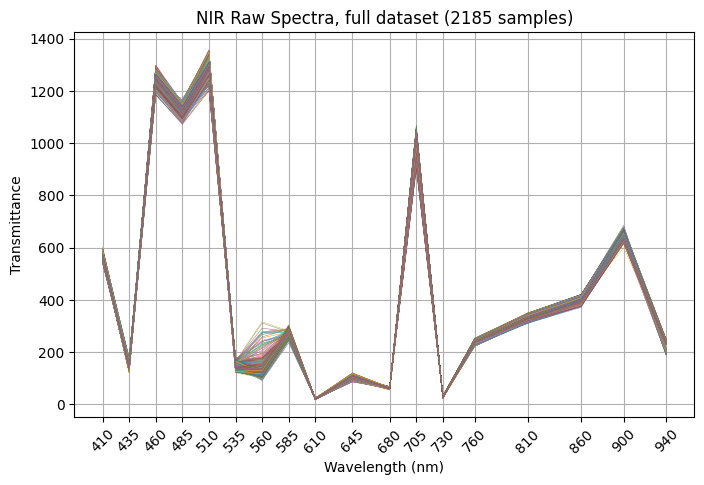

In [17]:
# Plot phổ (không tính Calib)
df_for_plot = df_hcmut[(df_hcmut['Sample_ID'] != 'Calib')]
spectra_plot (df_for_plot[wavelengths], 'NIR Raw Spectra, full dataset')

### **Xử lý, phân tích dữ liệu**

#### **Xử lý, phân tích với phổ đã chuẩn hóa**

In [18]:
df_normalized = df_hcmut.copy()
group_id = (df_normalized['Sample_ID'] == 'Calib').cumsum()
df_normalized[wavelengths] = df_normalized.groupby(group_id)[wavelengths].transform(
    lambda x: -np.log(x / x.iloc[0])
)

In [19]:
# Lọc bỏ các dòng calib
df_normalized = df_normalized[(df_normalized['Sample_ID'] != 'Calib')]
df_normalized.shape

(2185, 24)

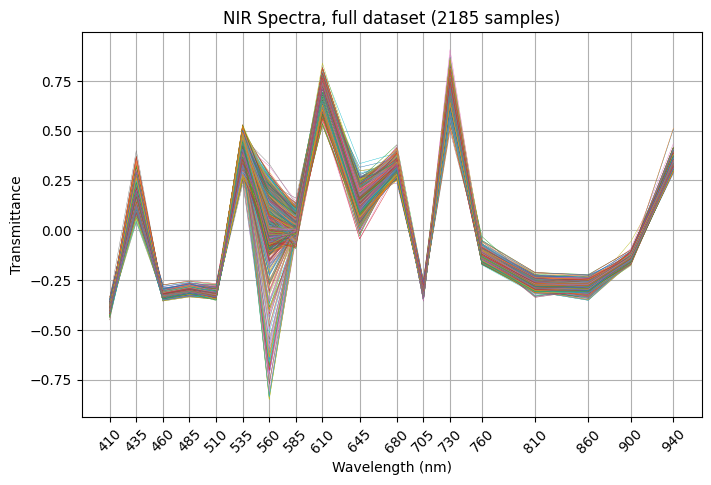

In [20]:
spectra_plot(df_normalized[wavelengths], 'NIR Spectra, full dataset')

In [ ]:
ph_stats = df_normalized['pH (Horiba)']
print("Giá trị lớn nhất:", ph_stats.max())
print("Giá trị nhỏ nhất:", ph_stats.min())
print("Giá trị trung bình:", ph_stats.mean())
print("Độ lệch chuẩn:", ph_stats.std())

Giá trị lớn nhất: 9.98
Giá trị nhỏ nhất: 2.97
Giá trị trung bình: 6.550723112128146
Độ lệch chuẩn: 2.0089492608194663


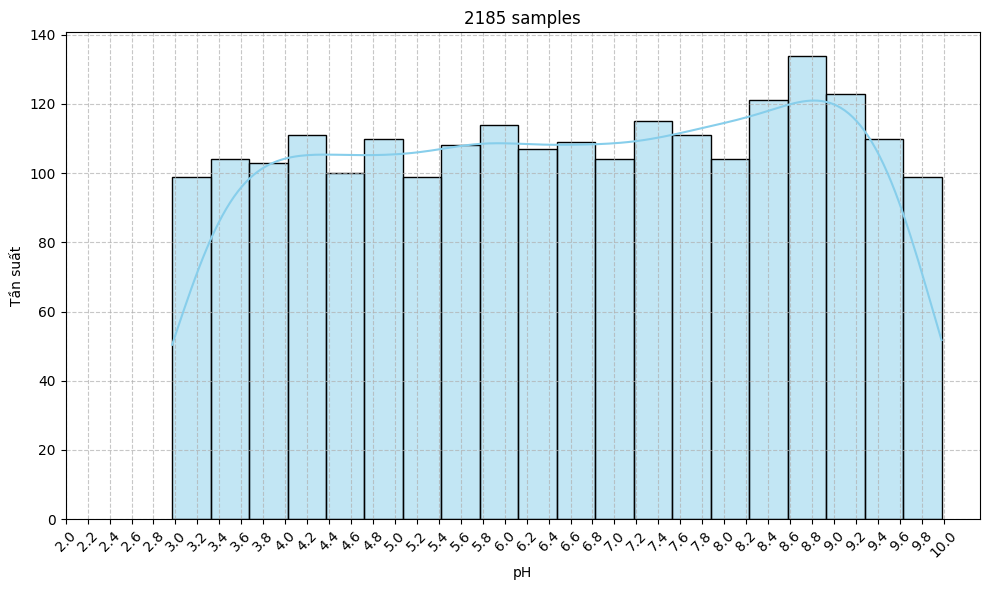

In [ ]:
pH_KDEplot(df_normalized['pH (Horiba)'], title=f'{df_normalized.shape[0]} samples')

#### **Xử lý, phân tích với phổ gốc**

In [ ]:
# Lọc bỏ các dòng calib
df_raw = df_hcmut[(df_hcmut['Sample_ID'] != 'Calib')]

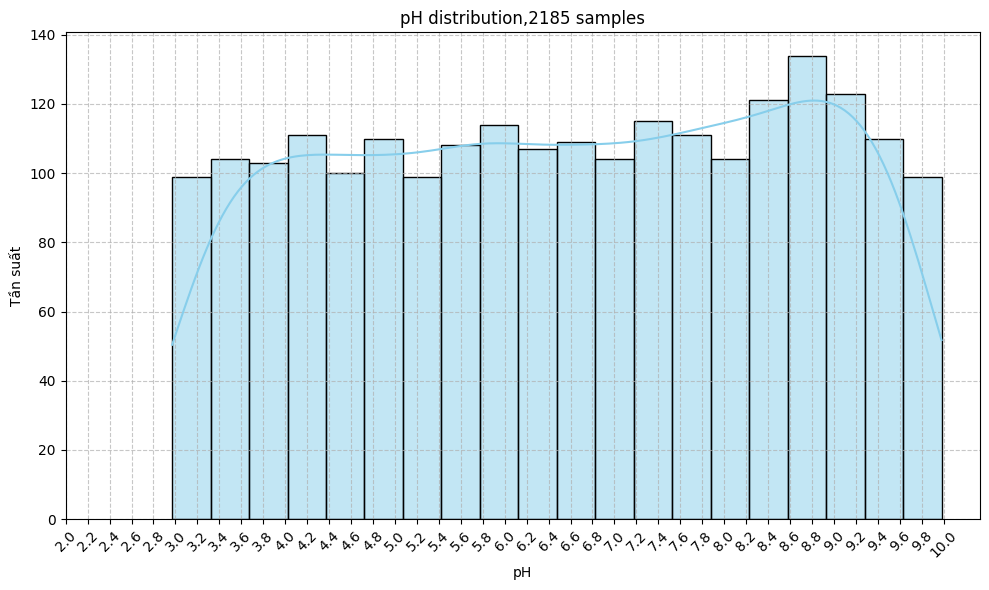

In [ ]:
pH_KDEplot(df_raw['pH (Horiba)'], title=f'pH distribution,{df_raw.shape[0]} samples', save_fig=0)

### **Training**

#### **Chia tập training, testing**

In [22]:
df_sorted = df_normalized.set_index('Sample_ID').sort_values(by='pH (Horiba)')
df_sorted['Group_ID'] = df_sorted.groupby("pH (Horiba)").ngroup()

is_train = df_sorted['Group_ID'] % 3 < 2
is_test = df_sorted['Group_ID'] % 3 == 2

X_train = df_sorted.loc[is_train, wavelengths]
y_train = df_sorted.loc[is_train, 'pH (Horiba)']

X_test = df_sorted.loc[is_test, wavelengths]
y_test = df_sorted.loc[is_test, 'pH (Horiba)']

print(f"Train size: {len(X_train)}")
print(f"Test size: {len(X_test)}")

Train size: 1441
Test size: 744


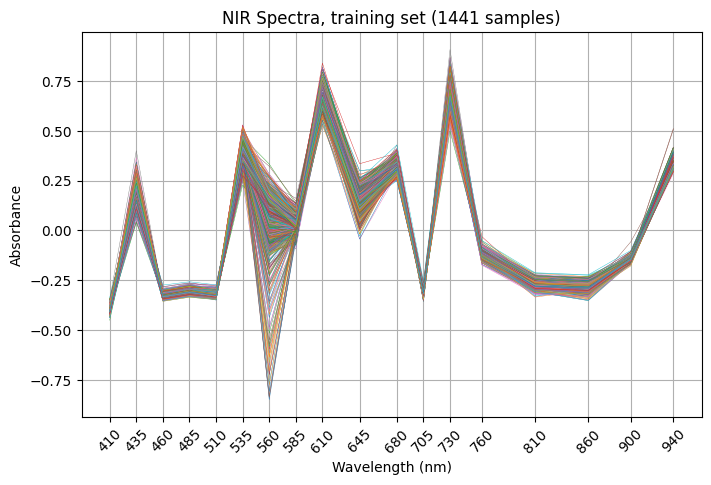

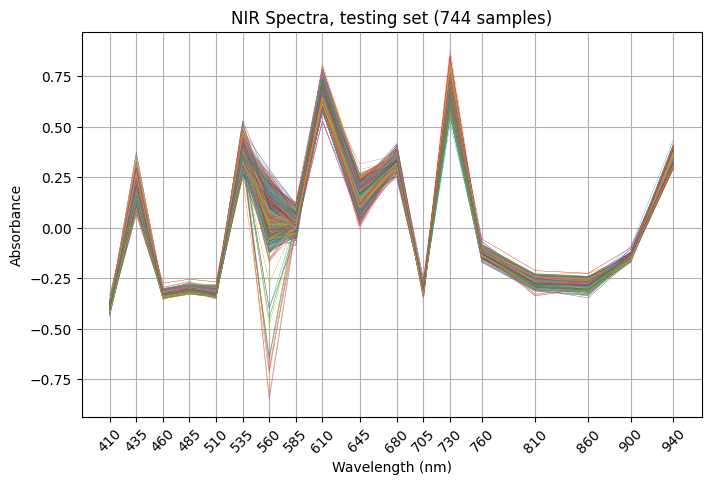

In [23]:
spectra_plot (pd.DataFrame(X_train, columns=wavelengths), 'NIR Spectra, training set')
spectra_plot (pd.DataFrame(X_test, columns=wavelengths), 'NIR Spectra, testing set')

#### **Tiền xử lý**

##### **Standard Normal Variate**

In [27]:
snv = StandardNormalVariate()
X_train_snv = snv.fit_transform(X_train)
X_test_snv = snv.transform(X_test)

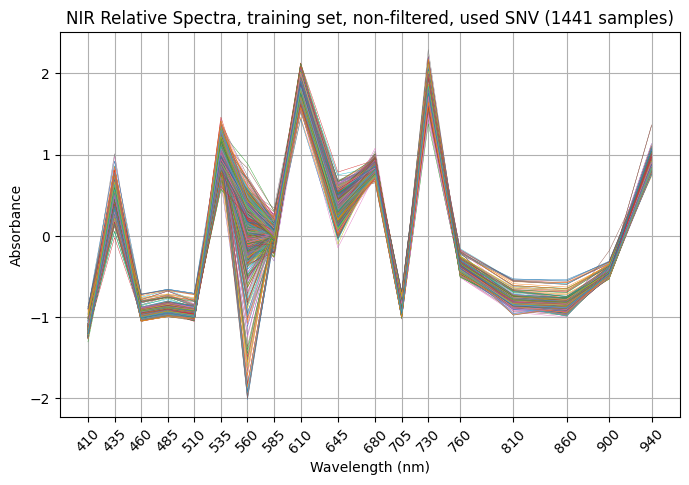

In [28]:
spectra_plot(pd.DataFrame(X_train_snv, columns=wavelengths), 'NIR Spectra, training set, non-filtered, used SNV')

##### **Multiplicative Scatter Correction**

In [29]:
msc = MultiplicativeScatterCorrection()
X_train_msc = msc.fit_transform(X_train)
X_test_msc = msc.transform(X_test)

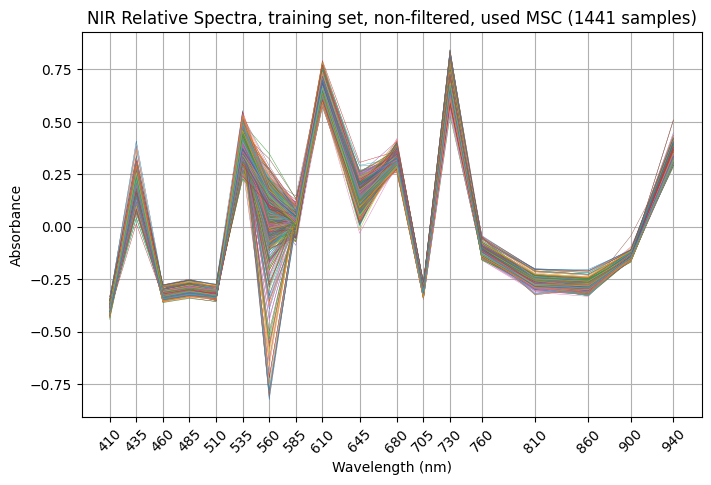

In [30]:
spectra_plot (pd.DataFrame(X_train_msc, columns=wavelengths), 'NIR Spectra, training set, non-filtered, used MSC')

##### **Standard Scaler**

In [31]:
ss = StandardScaler()
X_train_ss = ss.fit_transform(X_train)
X_test_ss = ss.transform(X_test)

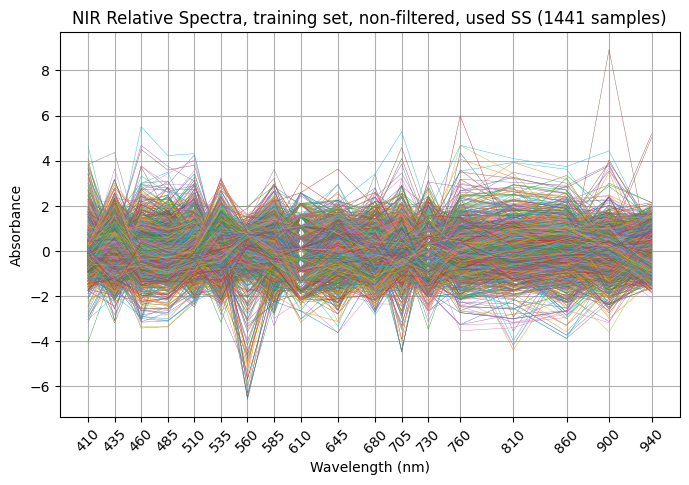

In [32]:
spectra_plot (pd.DataFrame(X_train_ss, columns=wavelengths),
              'NIR Spectra, training set, non-filtered, used SS')

##### **Robust Scaler**

In [33]:
rs = RobustScaler()
X_train_rs = rs.fit_transform(X_train)
X_test_rs = rs.transform(X_test)

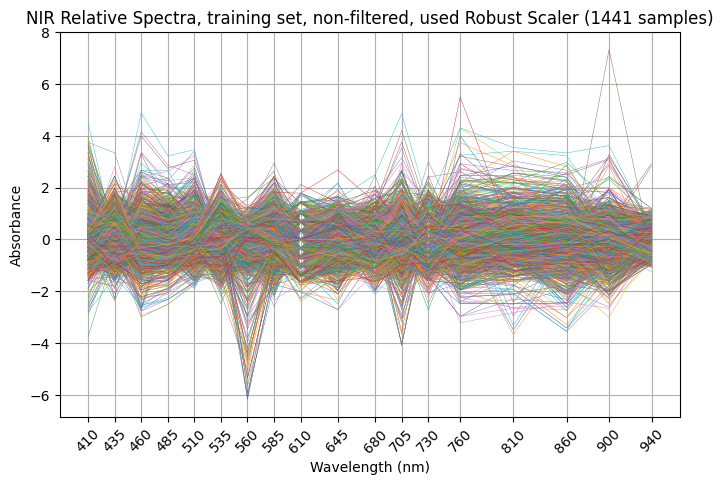

In [34]:
spectra_plot (pd.DataFrame(X_train_rs, columns=wavelengths),
              'NIR Spectra, training set, non-filtered, used Robust Scaler')

##### **MinMax Scaler**

In [35]:
mm = MinMaxScaler()
X_train_mm = mm.fit_transform(X_train)
X_test_mm = mm.transform(X_test)

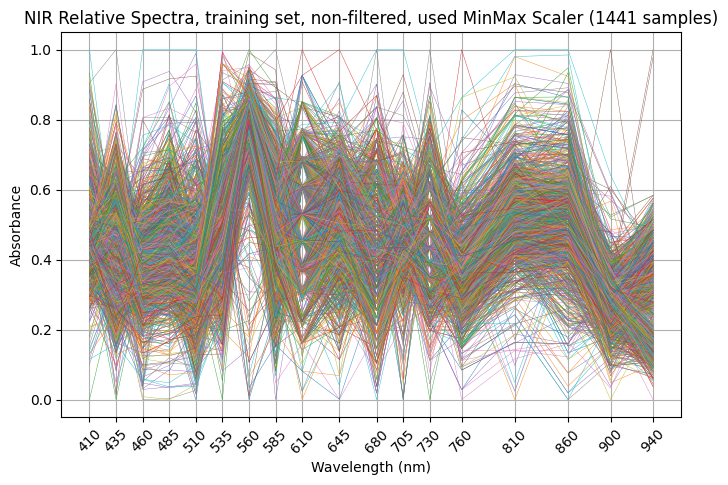

In [36]:
spectra_plot (pd.DataFrame(X_train_mm, columns=wavelengths),
              'NIR Spectra, training set, non-filtered, used MinMax Scaler')

##### **MRMR**

In [55]:
k_features = 4
mrmr_selected_features = mrmr.mrmr_regression(X=X_train, y=y_train, K=k_features)
print("Các bước sóng được chọn bởi MRMR:", mrmr_selected_features)

100%|██████████| 4/4 [00:00<00:00, 41.12it/s]

Các bước sóng được chọn bởi MRMR: [np.int64(610), np.int64(485), np.int64(680), np.int64(900)]


#### **Support Vector Regression**

In [37]:
def svr_val_evaluate(X_train, X_val, y_train, y_val, log_C, log_gamma, epsilon):
    """
    Huấn luyện SVR trên tập Train và đánh giá hiệu năng (-MSE) trên tập Val.
    """
    C_val = 10 ** log_C
    gamma_val = 10 ** log_gamma
    model = SVR(
        kernel='rbf',
        C=C_val,
        gamma=gamma_val,
        epsilon=epsilon
    )
    model.fit(X_train, y_train)
    y_val_pred = model.predict(X_val)
    val_mse = mean_squared_error(y_val, y_val_pred)
    return -val_mse

In [38]:
svr_training = pd.DataFrame(columns=['Method', 'Validation -MSE', 'Best_C', 'Best_gamma', 'Best_epsilon'])

##### **SVR with raw data**

In [39]:
pbounds = {
    'log_C': (0, 3.0),
    'log_gamma': (-3.0, 1.0),
    'epsilon': (0.001, 1.0)
}

def objective_wrapper (log_C, log_gamma, epsilon):
  return svr_val_evaluate(X_train, X_test, y_train, y_test, log_C, log_gamma, epsilon)

optimizer = BayesianOptimization(f=objective_wrapper, pbounds=pbounds,
                                 random_state=42, verbose=2)
optimizer.maximize(init_points=5, n_iter=200)

print(f"Best params: {optimizer.max['params']}")
p, target = optimizer.max['params'], optimizer.max['target']
svr_training.loc[len(svr_training)] = ['SVR + raw data', target, 10**p['log_C'], 10**p['log_gamma'], p['epsilon']]

|   iter    |  target   |   log_C   | log_gamma |  epsilon  |
-------------------------------------------------------------
| 1         | -2.276632 | 1.1236203 | 0.8028572 | 0.7322619 |
| 2         | -3.627282 | 1.7959754 | -2.375925 | 0.1568385 |
| 3         | -2.934273 | 0.1742508 | 0.4647045 | 0.6015138 |
| 4         | -3.728497 | 2.1242177 | -2.917662 | 0.9699399 |
| 5         | -3.136858 | 2.4973279 | -2.150643 | 0.1826431 |
| 6         | -1.883668 | 2.0129220 | 0.8300252 | 0.5518445 |
| 7         | -1.735001 | 3.0       | 1.0       | 1.0       |
| 8         | -1.874385 | 3.0       | 1.0       | 0.001     |
| 9         | -2.255794 | 3.0       | -0.057478 | 1.0       |
| 10        | -1.766192 | 2.3119317 | 1.0       | 1.0       |
| 11        | -1.863389 | 2.0335737 | 1.0       | 0.001     |
| 12        | -1.717662 | 2.6688397 | 1.0       | 0.6380637 |
| 13        | -1.703992 | 2.7069809 | 1.0       | 0.9347236 |
| 14        | -1.703414 | 2.7955281 | 1.0       | 0.8169268 |
| 15    

In [40]:
svr_training

,Method,Validation -MSE,Best_C,Best_gamma,Best_epsilon
0,SVR + raw data,-1.69828,673.854792,10.0,0.84929


--- SVR, (C, gamma, epsilon) = (673.85, 10.00, 0.85) ---
Training RMSE: 1.043
Testing RMSE: 1.3032
Training R²: 0.7303
Testing R²: 0.5788


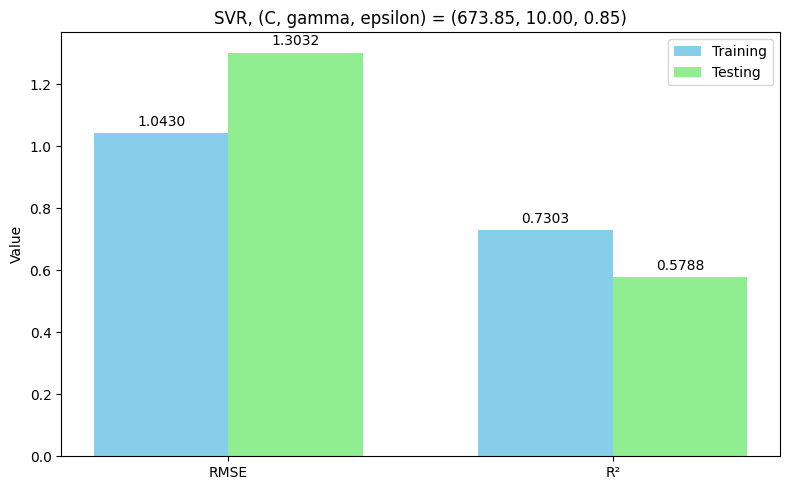

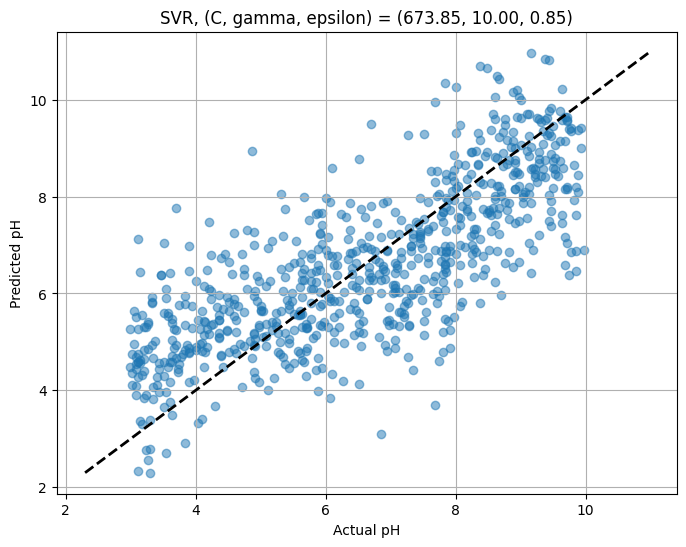

In [42]:
C, gamma, epsilon = svr_training.loc[svr_training['Method'] == "SVR + raw data"
                                    , ['Best_C', 'Best_gamma', 'Best_epsilon']].iloc[-1]
svr = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(X_train, y_train)
metrics_calculation(svr, X_train, y_train, X_test, y_test,
                    f'SVR, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',
                    f'SVR, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})', False, True)

##### **SVR + SS + PCA**

###### **`n_components = 4`**

In [ ]:
pca_4 = PCA(n_components=4)
X_train_pca_4 = pca_4.fit_transform(X_train_ss)
X_val_pca_4 = pca_4.transform(X_val_ss)
X_test_pca_4 = pca_4.transform(X_test_ss)

In [ ]:
pbounds = {
    'log_C': (0, 3.0),       # C: 10^-2 = 0.01 đến 10^3 = 1000
    'log_gamma': (-3.0, 1.0),   # gamma: 10^-4 = 0.0001 đến 10^2 = 100
    'epsilon': (0.001, 1.0)     # epsilon: 0.001 đến 1.0
}

def objective_wrapper (log_C, log_gamma, epsilon):
  return svr_val_evaluate(X_train_pca_4, X_val_pca_4, y_train, y_val, log_C, log_gamma, epsilon)

optimizer = BayesianOptimization(f=objective_wrapper, pbounds=pbounds,
                                 random_state=42, verbose=2)
optimizer.maximize(init_points=5, n_iter=200)

print(f"Best params: {optimizer.max['params']}")
p, target = optimizer.max['params'], optimizer.max['target']
svr_training.loc[len(svr_training)] = ['SVR + SS + PCA_4', target, 10**p['log_C'], 10**p['log_gamma'], p['epsilon']]

|   iter    |  target   |   log_C   | log_gamma |  epsilon  |
-------------------------------------------------------------
| 1         | -3.523319 | 1.1236203 | 0.8028572 | 0.7322619 |
| 2         | -2.944914 | 1.7959754 | -2.375925 | 0.1568385 |
| 3         | -3.026336 | 0.1742508 | 0.4647045 | 0.6015138 |
| 4         | -3.217368 | 2.1242177 | -2.917662 | 0.9699399 |
| 5         | -2.551916 | 2.4973279 | -2.150643 | 0.1826431 |
| 6         | -2.340120 | 2.3751280 | -1.839323 | 0.001     |
| 7         | -2.550553 | 2.9569420 | -1.296007 | 0.001     |
| 8         | -2.355774 | 1.9317255 | -1.063531 | 0.001     |
| 9         | -2.240916 | 2.3100633 | -1.163703 | 1.0       |
| 10        | -5.552012 | 3.0       | -0.334802 | 1.0       |
| 11        | -2.218475 | 1.5504934 | -1.422461 | 0.9441878 |
| 12        | -2.285957 | 0.4601250 | -1.249803 | 0.001     |
| 13        | -2.719453 | 0.0       | -1.642683 | 1.0       |
| 14        | -3.563501 | 0.0       | -2.498954 | 0.001     |
| 15    

In [ ]:
svr_training

,Method,Validation -MSE,Best_C,Best_gamma,Best_epsilon
0,SVR + raw normalized data,-1.218895,23.015294,0.001585,0.413544
1,SVR + SS + PCA_4,-2.094891,7.172396,0.150601,0.573946


--- SVR + SS + PCA (n_components = 4), (C, gamma, epsilon) = (7.17, 0.15, 0.57) ---
Training RMSE: 1.2744
Testing RMSE: 1.4854
Training R²: 0.5975
Testing R²: 0.4524


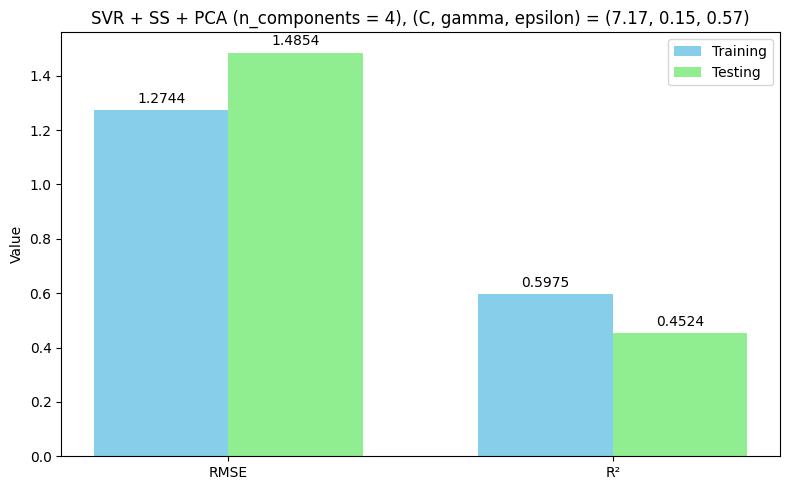

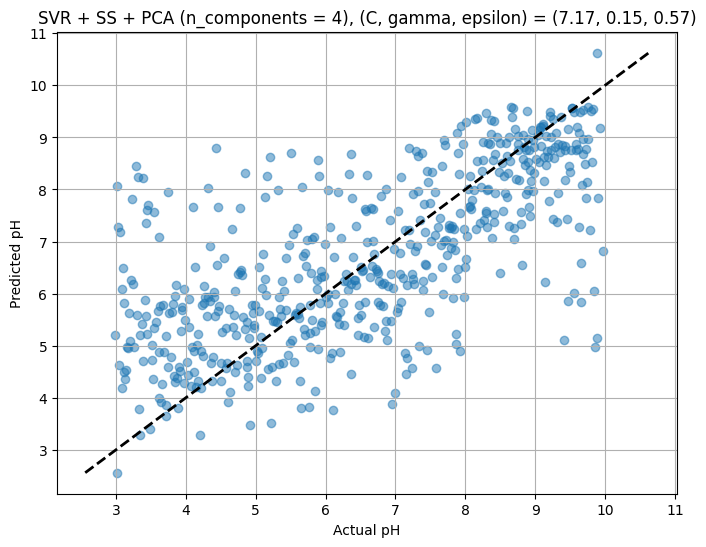

In [ ]:
X_train_val_pca_4 = np.vstack((X_train_pca_4, X_val_pca_4))
C, gamma, epsilon = svr_training.loc[svr_training['Method'] == "SVR + SS + PCA_4"
                                    , ['Best_C', 'Best_gamma', 'Best_epsilon']].iloc[-1]
svr_pca_4 = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(X_train_val_pca_4, y_train_val)
metrics_calculation(svr_pca_4, X_train_val_pca_4, y_train_val, X_test_pca_4, y_test,
                    f'SVR + SS + PCA (n_components = 4), (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',
                    f'SVR + SS + PCA (n_components = 4), (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})', 0, 1)

###### **`n_components = 8`**

In [ ]:
pca_8 = PCA(n_components=8)
X_train_pca_8 = pca_8.fit_transform(X_train_ss)
X_val_pca_8 = pca_8.transform(X_val_ss)
X_test_pca_8 = pca_8.transform(X_test_ss)

In [ ]:
X_train_pca_8.shape

(1093, 8)

In [ ]:
pbounds = {
    'log_C': (0, 3.0),       # C: 10^-2 = 0.01 đến 10^3 = 1000
    'log_gamma': (-3.0, 1.0),   # gamma: 10^-4 = 0.0001 đến 10^2 = 100
    'epsilon': (0.001, 1.0)     # epsilon: 0.001 đến 1.0
}

def objective_wrapper (log_C, log_gamma, epsilon):
  return svr_val_evaluate(X_train_pca_8, X_val_pca_8, y_train, y_val, log_C, log_gamma, epsilon)

optimizer = BayesianOptimization(f=objective_wrapper, pbounds=pbounds,
                                 random_state=42, verbose=2)
optimizer.maximize(init_points=5, n_iter=200)

print(f"Best params: {optimizer.max['params']}")
p, target = optimizer.max['params'], optimizer.max['target']
svr_training.loc[len(svr_training)] = ['SVR + SS + PCA_8', target, 10**p['log_C'], 10**p['log_gamma'], p['epsilon']]

|   iter    |  target   |   log_C   | log_gamma |  epsilon  |
-------------------------------------------------------------
| 1         | -3.687446 | 1.1236203 | 0.8028572 | 0.7322619 |
| 2         | -2.378567 | 1.7959754 | -2.375925 | 0.1568385 |
| 3         | -3.207741 | 0.1742508 | 0.4647045 | 0.6015138 |
| 4         | -2.731763 | 2.1242177 | -2.917662 | 0.9699399 |
| 5         | -1.983798 | 2.4973279 | -2.150643 | 0.1826431 |
| 6         | -3.026926 | 3.0       | -1.149060 | 0.001     |
| 7         | -2.332345 | 2.9151654 | -2.765472 | 0.001     |
| 8         | -1.767037 | 3.0       | -2.117002 | 0.9367343 |
| 9         | -1.685859 | 2.3053196 | -1.654751 | 1.0       |
| 10        | -2.806967 | 0.0       | -1.980620 | 1.0       |
| 11        | -1.651983 | 1.5332844 | -1.295151 | 1.0       |
| 12        | -1.740396 | 1.2867300 | -1.205043 | 0.0368907 |
| 13        | -1.961606 | 2.0851464 | -0.760435 | 1.0       |
| 14        | -1.822292 | 0.3224827 | -1.094839 | 0.001     |
| 15    

In [ ]:
svr_training

,Method,Validation -MSE,Best_C,Best_gamma,Best_epsilon
0,SVR + raw normalized data,-1.218895,23.015294,0.001585,0.413544
1,SVR + SS + PCA_4,-2.094891,7.172396,0.150601,0.573946
2,SVR + SS + PCA_8,-1.591236,14.027896,0.119645,0.591784


--- SVR + SS + PCA (n_components = 8), (C, gamma, epsilon) = (14.03, 0.12, 0.59) ---
Training RMSE: 0.9728
Testing RMSE: 1.2789
Training R²: 0.7655
Testing R²: 0.5941


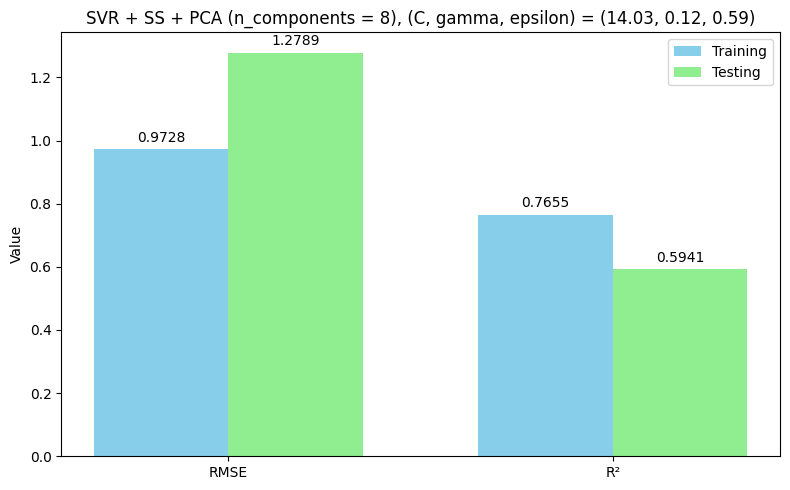

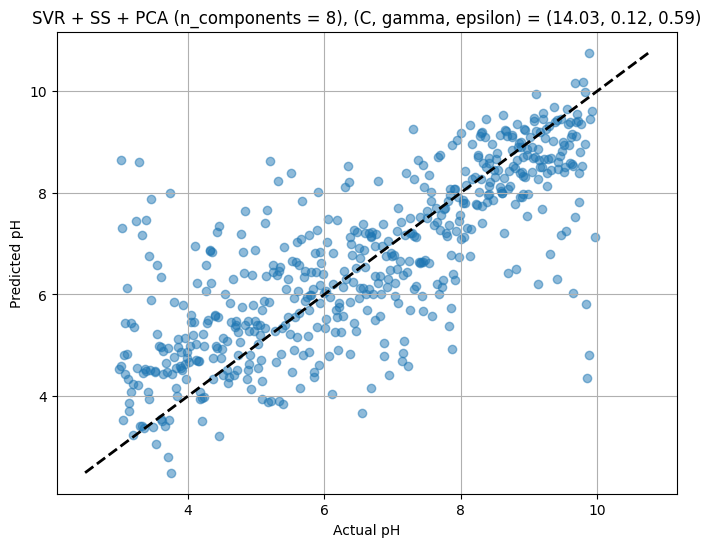

In [ ]:
X_train_val_pca_8 = np.vstack((X_train_pca_8, X_val_pca_8))
C, gamma, epsilon = svr_training.loc[svr_training['Method'] == "SVR + SS + PCA_8"
                                    , ['Best_C', 'Best_gamma', 'Best_epsilon']].iloc[-1]
svr_pca_8 = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(X_train_val_pca_8, y_train_val)
metrics_calculation(svr_pca_8, X_train_val_pca_8, y_train_val, X_test_pca_8, y_test,
                    f'SVR + SS + PCA (n_components = 8), (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',
                    f'SVR + SS + PCA (n_components = 8), (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})', 0, 1)

###### **`n_components = 10`**

In [ ]:
pca_10 = PCA(n_components=10)
X_train_pca_10 = pca_10.fit_transform(X_train_ss)
X_val_pca_10 = pca_10.transform(X_val_ss)
X_test_pca_10 = pca_10.transform(X_test_ss)

In [ ]:
pbounds = {
    'log_C': (0, 3.0),       # C: 10^0 = 1 đến 10^3 = 1000
    'log_gamma': (-3.0, 1.0),   # gamma: 10^-3 đến 10^1
    'epsilon': (0.001, 1.0)     # epsilon: 0.001 đến 1.0
}

def objective_wrapper (log_C, log_gamma, epsilon):
  return svr_val_evaluate(X_train_pca_10, X_val_pca_10, y_train, y_val, log_C, log_gamma, epsilon)

optimizer = BayesianOptimization(f=objective_wrapper, pbounds=pbounds,
                                 random_state=42, verbose=2)
optimizer.maximize(init_points=5, n_iter=200)

print(f"Best params: {optimizer.max['params']}")
p, target = optimizer.max['params'], optimizer.max['target']
svr_training.loc[len(svr_training)] = ['SVR + SS + PCA_10', target, 10**p['log_C'], 10**p['log_gamma'], p['epsilon']]

|   iter    |  target   |   log_C   | log_gamma |  epsilon  |
-------------------------------------------------------------
| 1         | -3.757691 | 1.1236203 | 0.8028572 | 0.7322619 |
| 2         | -2.204576 | 1.7959754 | -2.375925 | 0.1568385 |
| 3         | -3.309476 | 0.1742508 | 0.4647045 | 0.6015138 |
| 4         | -2.592396 | 2.1242177 | -2.917662 | 0.9699399 |
| 5         | -1.858132 | 2.4973279 | -2.150643 | 0.1826431 |
| 6         | -2.865997 | 3.0       | -1.010106 | 0.001     |
| 7         | -2.317011 | 3.0       | -2.989729 | 0.001     |
| 8         | -1.621908 | 3.0       | -1.998960 | 1.0       |
| 9         | -1.580561 | 2.1694144 | -1.559061 | 1.0       |
| 10        | -2.826280 | 0.0       | -2.051090 | 1.0       |
| 11        | -1.961170 | 2.8470943 | -1.287095 | 1.0       |
| 12        | -1.592232 | 1.4078277 | -1.310625 | 1.0       |
| 13        | -1.625182 | 1.2700009 | -1.256206 | 0.001     |
| 14        | -1.729841 | 0.3086538 | -1.162228 | 0.001     |
| 15    

In [ ]:
svr_training

,Method,Validation -MSE,Best_C,Best_gamma,Best_epsilon
0,SVR + raw normalized data,-1.218895,23.015294,0.001585,0.413544
1,SVR + SS + PCA_4,-2.094891,7.172396,0.150601,0.573946
2,SVR + SS + PCA_8,-1.591236,14.027896,0.119645,0.591784
3,SVR + SS + PCA_10,-1.475780,34.942988,0.088083,0.555575


--- SVR + SS + PCA (n_components = 10), (C, gamma, epsilon) = (34.94, 0.09, 0.56) ---
Training RMSE: 0.8739
Testing RMSE: 1.2174
Training R²: 0.8108
Testing R²: 0.6322


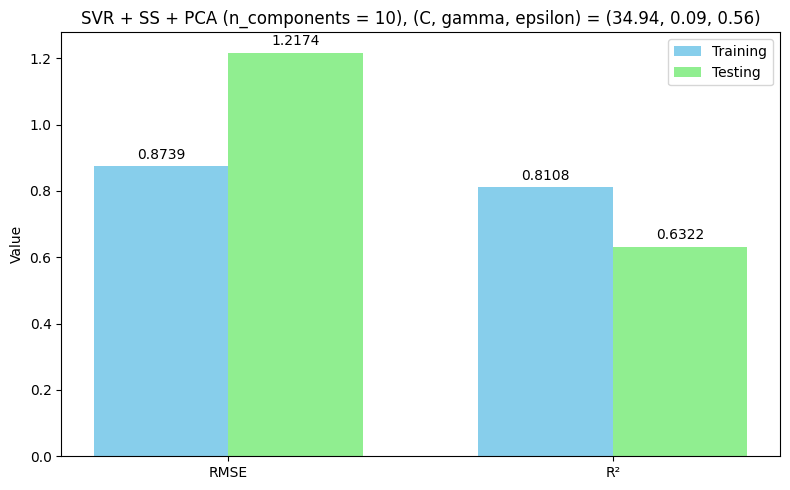

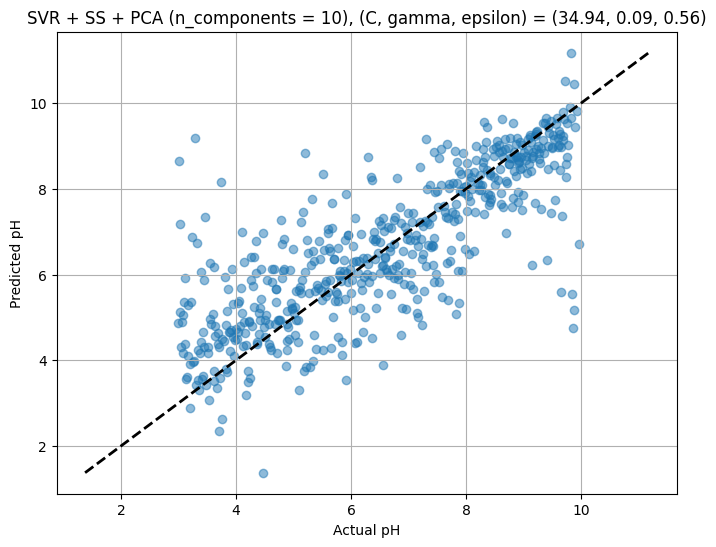

In [ ]:
X_train_val_pca_10 = np.vstack((X_train_pca_10, X_val_pca_10))
C, gamma, epsilon = svr_training.loc[svr_training['Method'] == "SVR + SS + PCA_10"
                                    , ['Best_C', 'Best_gamma', 'Best_epsilon']].iloc[-1]
svr_pca_10 = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(X_train_val_pca_10, y_train_val)
metrics_calculation(svr_pca_10, X_train_val_pca_10, y_train_val, X_test_pca_10, y_test,
                    f'SVR + SS + PCA (n_components = 10), (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',
                    f'SVR + SS + PCA (n_components = 10), (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})', 0, 1)

###### **`n_components = 14`**

In [ ]:
pca_14 = PCA(n_components=14)
X_train_pca_14 = pca_14.fit_transform(X_train_ss)
X_val_pca_14 = pca_14.transform(X_val_ss)
X_test_pca_14 = pca_14.transform(X_test_ss)

In [ ]:
pbounds = {
    'log_C': (0, 3.0),       # C: 10^0 = 1 đến 10^3 = 1000
    'log_gamma': (-3.0, 1.0),   # gamma: 10^-3 đến 10^1
    'epsilon': (0.001, 1.0)     # epsilon: 0.001 đến 1.0
}

def objective_wrapper (log_C, log_gamma, epsilon):
  return svr_val_evaluate(X_train_pca_14, X_val_pca_14, y_train, y_val, log_C, log_gamma, epsilon)

optimizer = BayesianOptimization(f=objective_wrapper, pbounds=pbounds,
                                 random_state=42, verbose=2)
optimizer.maximize(init_points=5, n_iter=200)

print(f"Best params: {optimizer.max['params']}")
p, target = optimizer.max['params'], optimizer.max['target']
svr_training.loc[len(svr_training)] = ['SVR + SS + PCA_14', target, 10**p['log_C'], 10**p['log_gamma'], p['epsilon']]

|   iter    |  target   |   log_C   | log_gamma |  epsilon  |
-------------------------------------------------------------
| 1         | -3.828990 | 1.1236203 | 0.8028572 | 0.7322619 |
| 2         | -1.977843 | 1.7959754 | -2.375925 | 0.1568385 |
| 3         | -3.435970 | 0.1742508 | 0.4647045 | 0.6015138 |
| 4         | -2.407280 | 2.1242177 | -2.917662 | 0.9699399 |
| 5         | -1.755541 | 2.4973279 | -2.150643 | 0.1826431 |
| 6         | -2.711544 | 3.0       | -0.891597 | 0.001     |
| 7         | -2.029355 | 3.0       | -3.0      | 0.001     |
| 8         | -3.507357 | 0.0       | -3.0      | 0.001     |
| 9         | -1.706236 | 3.0       | -1.960602 | 1.0       |
| 10        | -1.562336 | 1.9772937 | -1.539558 | 1.0       |
| 11        | -1.675963 | 0.9354229 | -1.509194 | 1.0       |
| 12        | -1.577693 | 1.2996018 | -1.305629 | 0.001     |
| 13        | -1.778814 | 0.0       | -1.157834 | 0.001     |
| 14        | -1.900252 | 0.0       | -1.239883 | 1.0       |
| 15    

In [ ]:
svr_training

,Method,Validation -MSE,Best_C,Best_gamma,Best_epsilon
0,SVR + raw normalized data,-1.218895,23.015294,0.001585,0.413544
1,SVR + SS + PCA_4,-2.094891,7.172396,0.150601,0.573946
2,SVR + SS + PCA_8,-1.591236,14.027896,0.119645,0.591784
3,SVR + SS + PCA_10,-1.475780,34.942988,0.088083,0.555575
4,SVR + SS + PCA_14,-1.373023,45.404255,0.081665,0.490364


--- SVR + SS + PCA (n_components = 14), (C, gamma, epsilon) = (45.40, 0.08, 0.49) ---
Training RMSE: 0.7473
Testing RMSE: 1.2355
Training R²: 0.8616
Testing R²: 0.6212


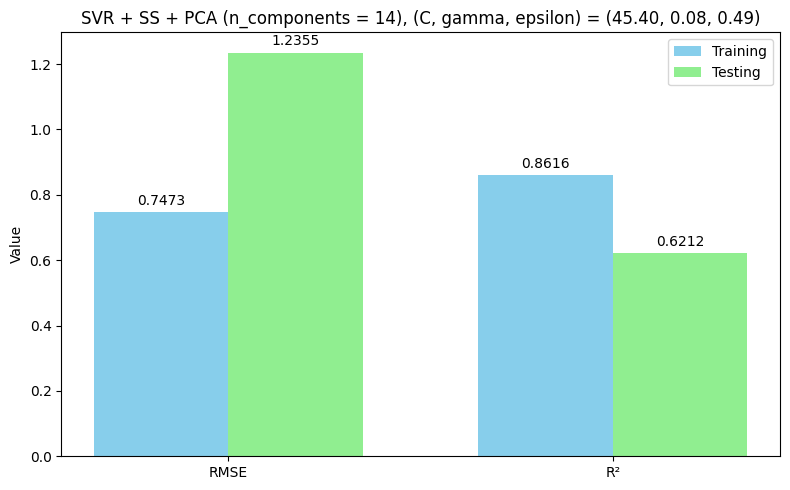

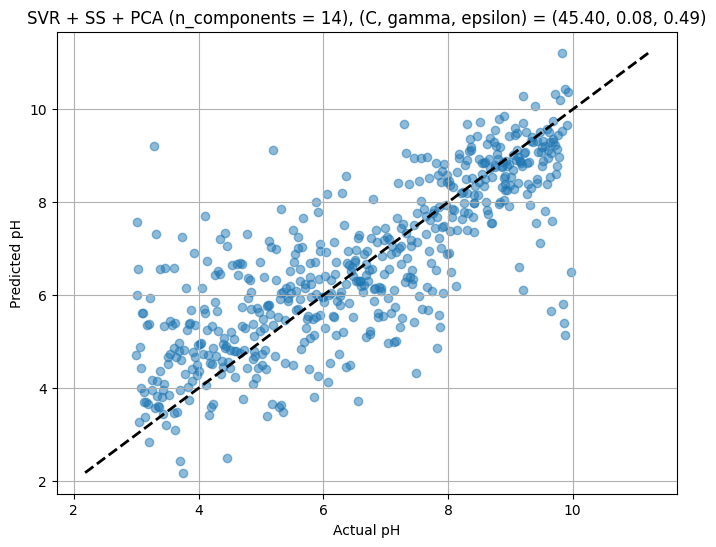

In [ ]:
X_train_val_pca_14 = np.vstack((X_train_pca_14, X_val_pca_14))
C, gamma, epsilon = svr_training.loc[svr_training['Method'] == "SVR + SS + PCA_14"
                                    , ['Best_C', 'Best_gamma', 'Best_epsilon']].iloc[-1]
svr_pca_14 = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(X_train_val_pca_14, y_train_val)

metrics_calculation(svr_pca_14, X_train_val_pca_14, y_train_val, X_test_pca_14, y_test,
                    f'SVR + SS + PCA (n_components = 14), (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',
                    f'SVR + SS + PCA (n_components = 14), (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})', 0, 1)

##### **SVR + SNV**

In [ ]:
pbounds = {
    'log_C': (0, 3.0),
    'log_gamma': (-3.0, 1.0),
    'epsilon': (0.001, 1.0)
}

def objective_wrapper (log_C, log_gamma, epsilon):
  return svr_val_evaluate(X_train_snv, X_test_snv, y_train, y_test, log_C, log_gamma, epsilon)

optimizer = BayesianOptimization(f=objective_wrapper, pbounds=pbounds,
                                 random_state=42, verbose=2)
optimizer.maximize(init_points=5, n_iter=200)

print(f"Best params: {optimizer.max['params']}")
p, target = optimizer.max['params'], optimizer.max['target']
svr_training.loc[len(svr_training)] = ['SVR + SNV', target, 10**p['log_C'], 10**p['log_gamma'], p['epsilon']]

|   iter    |  target   |   log_C   | log_gamma |  epsilon  |
-------------------------------------------------------------
| 1         | -1.991102 | 1.1236203 | 0.8028572 | 0.7322619 |
| 2         | -3.530852 | 1.7959754 | -2.375925 | 0.1568385 |
| 3         | -2.587213 | 0.1742508 | 0.4647045 | 0.6015138 |
| 4         | -3.600190 | 2.1242177 | -2.917662 | 0.9699399 |
| 5         | -3.121013 | 2.4973279 | -2.150643 | 0.1826431 |
| 6         | -2.290563 | 2.5103675 | 1.0       | 0.4406221 |
| 7         | -2.349354 | 1.9216589 | -0.054168 | 1.0       |
| 8         | -1.898423 | 1.3485031 | 1.0       | 0.001     |
| 9         | -2.186810 | 1.6363450 | 0.2304377 | 0.001     |
| 10        | -1.949741 | 1.6779838 | 1.0       | 1.0       |
| 11        | -2.006109 | 0.7565985 | 1.0       | 0.001     |
| 12        | -1.899448 | 1.4468981 | 1.0       | 0.4620095 |
| 13        | -1.980450 | 1.0729988 | 1.0       | 1.0       |
| 14        | -1.895490 | 1.1949229 | 1.0       | 0.2781532 |
| 15    

In [ ]:
svr_training

,Method,Validation -MSE,Best_C,Best_gamma,Best_epsilon
0,SVR + SNV + MSC,-1.764501,1000.000000,10.000000,0.908557
1,SVR + SNV + SS,-1.302129,13.814337,0.286202,0.444204
2,SVR + MSC + SS,-1.298329,13.672852,0.291585,0.439947
3,SVR + SNV + MSC + SS,-1.298302,13.749482,0.290728,0.440252
4,SVR + raw data,-1.692258,616.496870,10.000000,0.541995
5,SVR + SNV,-1.884651,17.343116,10.000000,0.001000


--- SVR + SNV, (C, gamma, epsilon) = (17.34, 10.00, 0.00) ---
Training RMSE: 0.9783
Testing RMSE: 1.3728
Training R²: 0.7628
Testing R²: 0.5326


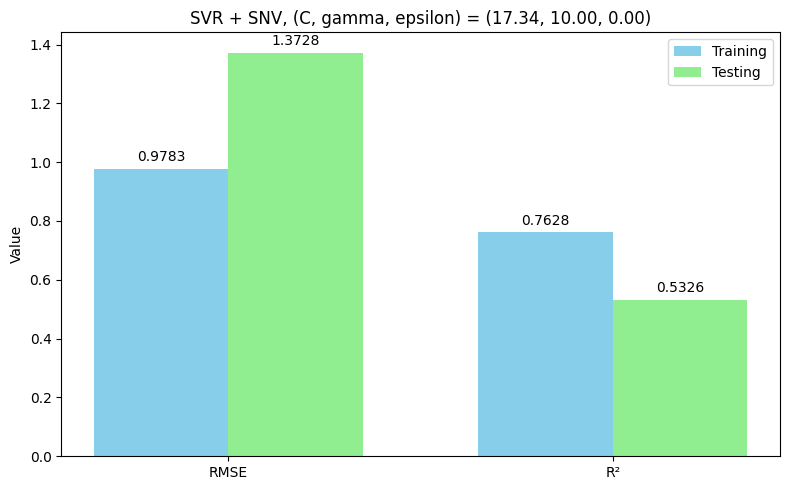

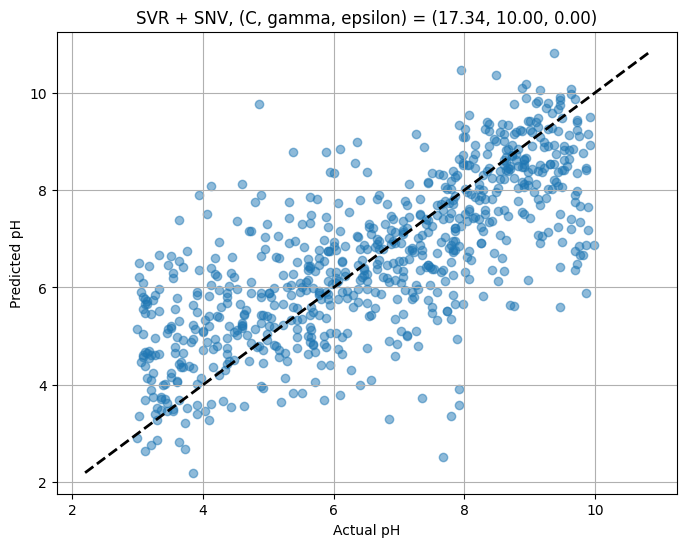

In [ ]:
C, gamma, epsilon = svr_training.loc[svr_training['Method'] == "SVR + SNV"
                                    , ['Best_C', 'Best_gamma', 'Best_epsilon']].iloc[-1]
svr_snv = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(X_train_snv, y_train)
metrics_calculation(svr_snv, X_train_snv, y_train, X_test_snv, y_test,
                    f'SVR + SNV, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',
                    f'SVR + SNV, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',0, 1)

In [ ]:
# calculate_and_plot_shap(svr_snv, X_train_snv, X_test_snv, wavelengths, 'SVR + SNV SHAP value summary plot', '', 1, 0)

##### **SVR + MSC**

In [ ]:
pbounds = {
    'log_C': (0, 3.0),
    'log_gamma': (-3.0, 1.0),
    'epsilon': (0.001, 1.0)
}

def objective_wrapper (log_C, log_gamma, epsilon):
  return svr_val_evaluate(X_train_msc, X_test_msc, y_train, y_test, log_C, log_gamma, epsilon)

optimizer = BayesianOptimization(f=objective_wrapper, pbounds=pbounds,
                                 random_state=42, verbose=2)
optimizer.maximize(init_points=5, n_iter=200)

print(f"Best params: {optimizer.max['params']}")
p, target = optimizer.max['params'], optimizer.max['target']
svr_training.loc[len(svr_training)] = ['SVR + MSC', target, 10**p['log_C'], 10**p['log_gamma'], p['epsilon']]

|   iter    |  target   |   log_C   | log_gamma |  epsilon  |
-------------------------------------------------------------
| 1         | -2.654592 | 1.1236203 | 0.8028572 | 0.7322619 |
| 2         | -3.908349 | 1.7959754 | -2.375925 | 0.1568385 |
| 3         | -3.308029 | 0.1742508 | 0.4647045 | 0.6015138 |
| 4         | -3.933105 | 2.1242177 | -2.917662 | 0.9699399 |
| 5         | -3.525893 | 2.4973279 | -2.150643 | 0.1826431 |
| 6         | -2.234427 | 2.0047561 | 1.0       | 0.7697498 |
| 7         | -2.161337 | 3.0       | 1.0       | 0.001     |
| 8         | -2.044780 | 3.0       | 1.0       | 1.0       |
| 9         | -2.415000 | 3.0       | 0.3163617 | 1.0       |
| 10        | -2.066588 | 3.0       | 1.0       | 0.6710961 |
| 11        | -2.060644 | 2.8109021 | 1.0       | 1.0       |
| 12        | -2.060644 | 2.8109021 | 1.0       | 1.0       |
| 13        | -2.060644 | 2.8109021 | 1.0       | 1.0       |
| 14        | -2.060644 | 2.8109021 | 1.0       | 1.0       |
| 15    

In [ ]:
svr_training

,Method,Validation -MSE,Best_C,Best_gamma,Best_epsilon
0,SVR + SNV + MSC,-1.764501,1000.000000,10.000000,0.908557
1,SVR + SNV + SS,-1.302129,13.814337,0.286202,0.444204
2,SVR + MSC + SS,-1.298329,13.672852,0.291585,0.439947
3,SVR + SNV + MSC + SS,-1.298302,13.749482,0.290728,0.440252
4,SVR + raw data,-1.692258,616.496870,10.000000,0.541995
5,SVR + SNV,-1.884651,17.343116,10.000000,0.001000
6,SVR + MSC,-2.044781,1000.000000,10.000000,1.000000


--- SVR + MSC, (C, gamma, epsilon) = (1000.00, 10.00, 1.00) ---
Training RMSE: 1.2046
Testing RMSE: 1.43
Training R²: 0.6403
Testing R²: 0.4929


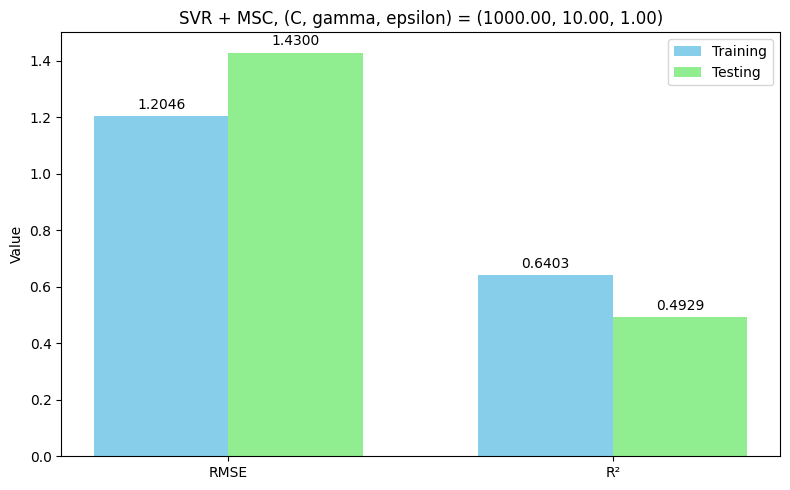

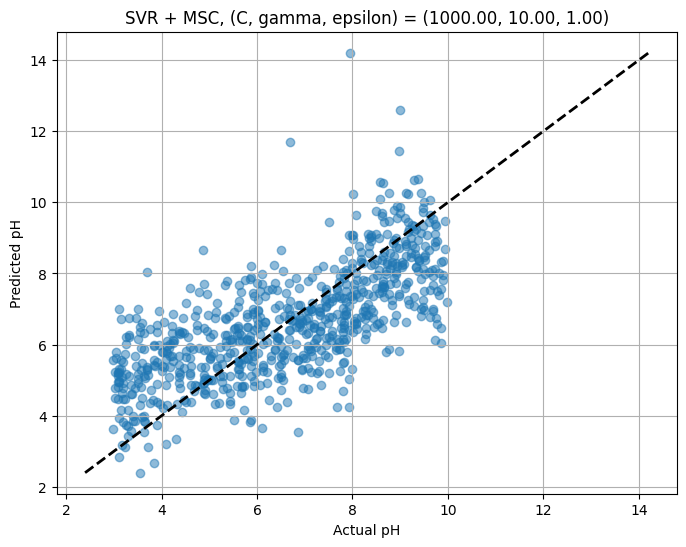

In [ ]:
C, gamma, epsilon = svr_training.loc[svr_training['Method'] == "SVR + MSC"
                                    , ['Best_C', 'Best_gamma', 'Best_epsilon']].iloc[-1]
svr_msc = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(X_train_msc, y_train)
metrics_calculation(svr_msc, X_train_msc, y_train, X_test_msc, y_test,
                    f'SVR + MSC, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',
                    f'SVR + MSC, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',0, 1)

##### **SVR + SNV + MSC**

In [46]:
snv_msc = MultiplicativeScatterCorrection()
X_train_snv_msc = snv_msc.fit_transform(X_train_snv)
X_test_snv_msc = snv_msc.transform(X_test_snv)

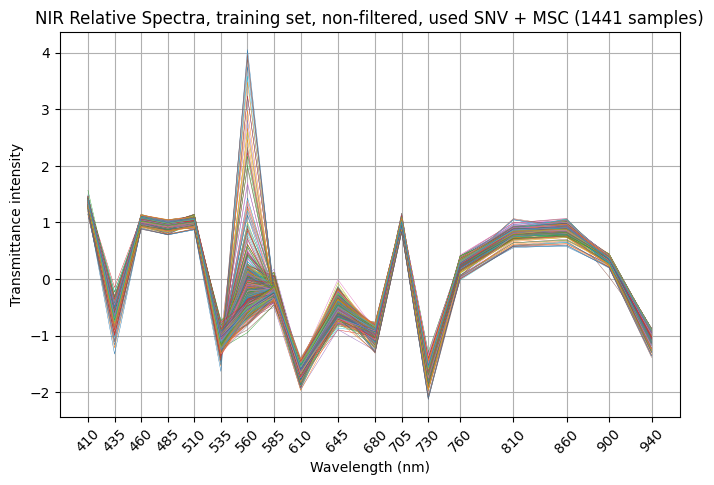

In [ ]:
spectra_plot (pd.DataFrame(X_train_snv_msc, columns=wavelengths), 'NIR Relative Spectra, training set, non-filtered, used SNV + MSC', 0)

In [ ]:
pbounds = {
    'log_C': (0, 3.0),
    'log_gamma': (-3.0, 1.0),
    'epsilon': (0.001, 1.0)
}

def objective_wrapper (log_C, log_gamma, epsilon):
  return svr_val_evaluate(X_train_snv_msc, X_test_snv_msc, y_train, y_test, log_C, log_gamma, epsilon)

optimizer = BayesianOptimization(f=objective_wrapper, pbounds=pbounds,
                                 random_state=42, verbose=2)
optimizer.maximize(init_points=5, n_iter=200)

print(f"Best params: {optimizer.max['params']}")
p, target = optimizer.max['params'], optimizer.max['target']
svr_training.loc[len(svr_training)] = ['SVR + SNV + MSC', target, 10**p['log_C'], 10**p['log_gamma'], p['epsilon']]

|   iter    |  target   |   log_C   | log_gamma |  epsilon  |
-------------------------------------------------------------
| 1         | -1.996543 | 1.1236203 | 0.8028572 | 0.7322619 |
| 2         | -3.515409 | 1.7959754 | -2.375925 | 0.1568385 |
| 3         | -2.586744 | 0.1742508 | 0.4647045 | 0.6015138 |
| 4         | -3.592476 | 2.1242177 | -2.917662 | 0.9699399 |
| 5         | -3.119311 | 2.4973279 | -2.150643 | 0.1826431 |
| 6         | -2.303366 | 2.5277416 | 1.0       | 0.4425822 |
| 7         | -2.381170 | 1.9106930 | -0.050819 | 1.0       |
| 8         | -1.891472 | 1.3523553 | 1.0       | 0.001     |
| 9         | -2.212958 | 1.6189394 | 0.2539417 | 0.001     |
| 10        | -1.945404 | 1.6770437 | 1.0       | 1.0       |
| 11        | -2.002744 | 0.7500327 | 1.0       | 0.001     |
| 12        | -1.895132 | 1.4481194 | 1.0       | 0.4574035 |
| 13        | -1.976862 | 1.0759504 | 1.0       | 1.0       |
| 14        | -1.893728 | 1.1969532 | 1.0       | 0.2631089 |
| 15    

In [ ]:
svr_training

,Method,Validation -MSE,Best_C,Best_gamma,Best_epsilon
0,SVR + SNV + MSC,-1.764501,1000.000000,10.000000,0.908557
1,SVR + SNV + SS,-1.302129,13.814337,0.286202,0.444204
2,SVR + MSC + SS,-1.298329,13.672852,0.291585,0.439947
3,SVR + SNV + MSC + SS,-1.298302,13.749482,0.290728,0.440252
4,SVR + raw data,-1.692258,616.496870,10.000000,0.541995
5,SVR + SNV,-1.884651,17.343116,10.000000,0.001000
6,SVR + MSC,-2.044781,1000.000000,10.000000,1.000000
7,SVR + SS,-1.632293,31.234211,0.134872,0.485393
8,SVR + SNV + SS,-1.656357,9.257217,0.243200,0.165935
9,SVR + MSC + SS,-1.576957,8.308608,0.220369,0.117070


--- SVR + SNV + MSC, (C, gamma, epsilon) = (17.91, 10.00, 0.00) ---
Training RMSE: 0.9764
Testing RMSE: 1.3702
Training R²: 0.7637
Testing R²: 0.5344


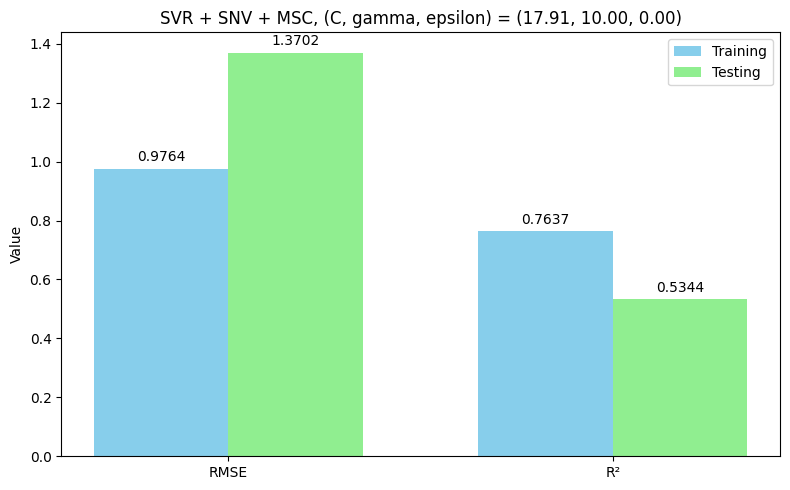

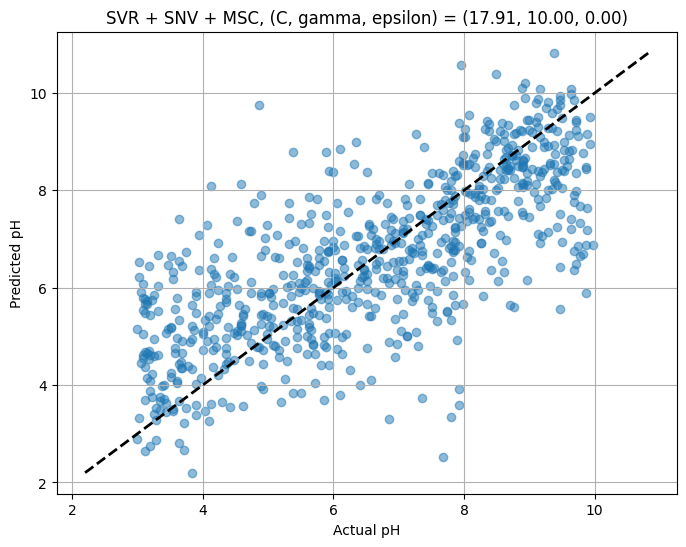

In [ ]:
C, gamma, epsilon = svr_training.loc[svr_training['Method'] == "SVR + SNV + MSC"
                                    , ['Best_C', 'Best_gamma', 'Best_epsilon']].iloc[-1]
svr_snv_msc = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(X_train_snv_msc, y_train)
metrics_calculation(svr_snv_msc, X_train_snv_msc, y_train, X_test_snv_msc, y_test,
                    f'SVR + SNV + MSC, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',
                    f'SVR + SNV + MSC, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',0, 1)

##### **SVR + SS**

In [43]:
pbounds = {
    'log_C': (0, 3.0),
    'log_gamma': (-3.0, 1.0),
    'epsilon': (0.001, 1.0)
}

def objective_wrapper (log_C, log_gamma, epsilon):
  return svr_val_evaluate(X_train_ss, X_test_ss, y_train, y_test, log_C, log_gamma, epsilon)

optimizer = BayesianOptimization(f=objective_wrapper, pbounds=pbounds,
                                 random_state=42, verbose=2)
optimizer.maximize(init_points=5, n_iter=200)

print(f"Best params: {optimizer.max['params']}")
p, target = optimizer.max['params'], optimizer.max['target']
svr_training.loc[len(svr_training)] = ['SVR + SS', target, 10**p['log_C'], 10**p['log_gamma'], p['epsilon']]

|   iter    |  target   |   log_C   | log_gamma |  epsilon  |
-------------------------------------------------------------
| 1         | -3.951647 | 1.1236203 | 0.8028572 | 0.7322619 |
| 2         | -2.230637 | 1.7959754 | -2.375925 | 0.1568385 |
| 3         | -3.789705 | 0.1742508 | 0.4647045 | 0.6015138 |
| 4         | -2.516276 | 2.1242177 | -2.917662 | 0.9699399 |
| 5         | -1.840832 | 2.4973279 | -2.150643 | 0.1826431 |
| 6         | -2.077494 | 3.0       | -0.896839 | 0.001     |
| 7         | -2.280703 | 3.0       | -3.0      | 0.001     |
| 8         | -2.445445 | 3.0       | -1.556296 | 1.0       |
| 9         | -3.260017 | 0.0       | -3.0      | 1.0       |
| 10        | -2.115844 | 2.1976128 | -1.418387 | 0.001     |
| 11        | -2.334293 | 3.0       | -1.840777 | 0.001     |
| 12        | -3.682053 | 3.0       | 0.5039556 | 0.001     |
| 13        | -1.820702 | 1.8135011 | -1.579997 | 1.0       |
| 14        | -1.922972 | 0.8424393 | -1.395625 | 1.0       |
| 15    

In [44]:
svr_training

,Method,Validation -MSE,Best_C,Best_gamma,Best_epsilon
0,SVR + raw data,-1.698280,673.854792,10.000000,0.849290
1,SVR + SS,-1.604395,26.216295,0.152266,0.367627


--- SVR + SS, (C, gamma, epsilon) = (26.22, 0.15, 0.37) ---
Training RMSE: 0.406
Testing RMSE: 1.2666
Training R²: 0.9591
Testing R²: 0.6021


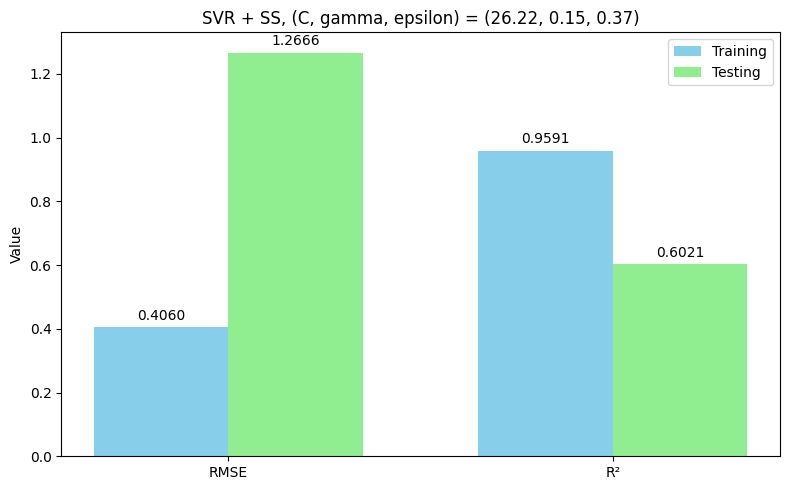

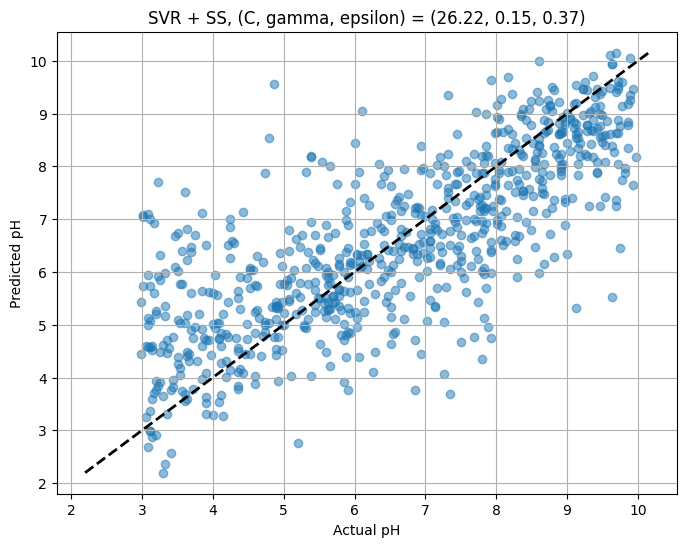

In [45]:
C, gamma, epsilon = svr_training.loc[svr_training['Method'] == "SVR + SS"
                                    , ['Best_C', 'Best_gamma', 'Best_epsilon']].iloc[-1]
svr_ss = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(X_train_ss, y_train)
metrics_calculation(svr_ss, X_train_ss, y_train, X_test_ss, y_test,
                    f'SVR + SS, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',
                    f'SVR + SS, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',False, True)

##### **SVR + SNV + SS**

In [ ]:
snv_ss = StandardScaler()
X_train_snv_ss = snv_ss.fit_transform(X_train_snv)
X_test_snv_ss = snv_ss.transform(X_test_snv)

In [ ]:
pbounds = {
    'log_C': (0, 3.0),
    'log_gamma': (-3.0, 1.0),
    'epsilon': (0.001, 1.0)
}

def objective_wrapper (log_C, log_gamma, epsilon):
  return svr_val_evaluate(X_train_snv_ss, X_test_snv_ss, y_train, y_test, log_C, log_gamma, epsilon)

optimizer = BayesianOptimization(f=objective_wrapper, pbounds=pbounds,
                                 random_state=42, verbose=2)
optimizer.maximize(init_points=5, n_iter=200)

print(f"Best params: {optimizer.max['params']}")
p, target = optimizer.max['params'], optimizer.max['target']
svr_training.loc[len(svr_training)] = ['SVR + SNV + SS', target, 10**p['log_C'], 10**p['log_gamma'], p['epsilon']]

|   iter    |  target   |   log_C   | log_gamma |  epsilon  |
-------------------------------------------------------------
| 1         | -3.876580 | 1.1236203 | 0.8028572 | 0.7322619 |
| 2         | -2.467797 | 1.7959754 | -2.375925 | 0.1568385 |
| 3         | -3.545709 | 0.1742508 | 0.4647045 | 0.6015138 |
| 4         | -2.737169 | 2.1242177 | -2.917662 | 0.9699399 |
| 5         | -2.065391 | 2.4973279 | -2.150643 | 0.1826431 |
| 6         | -3.564991 | 3.0       | -1.009417 | 0.001     |
| 7         | -2.469711 | 2.8893012 | -2.862213 | 0.001     |
| 8         | -2.096159 | 3.0       | -2.187617 | 1.0       |
| 9         | -3.570557 | 0.0       | -3.0      | 0.001     |
| 10        | -1.977159 | 2.1343108 | -1.717376 | 1.0       |
| 11        | -2.091740 | 1.0471245 | -1.465006 | 1.0       |
| 12        | -2.478689 | 0.0       | -1.370947 | 1.0       |
| 13        | -1.937870 | 1.0810450 | -1.242652 | 0.001     |
| 14        | -2.120370 | 0.1367253 | -1.089833 | 0.001     |
| 15    

In [ ]:
svr_training

,Method,Validation -MSE,Best_C,Best_gamma,Best_epsilon
0,SVR + SNV + MSC,-1.764501,1000.000000,10.000000,0.908557
1,SVR + SNV + SS,-1.302129,13.814337,0.286202,0.444204
2,SVR + MSC + SS,-1.298329,13.672852,0.291585,0.439947
3,SVR + SNV + MSC + SS,-1.298302,13.749482,0.290728,0.440252
4,SVR + raw data,-1.692258,616.496870,10.000000,0.541995
5,SVR + SNV,-1.884651,17.343116,10.000000,0.001000
6,SVR + MSC,-2.044781,1000.000000,10.000000,1.000000
7,SVR + SS,-1.632293,31.234211,0.134872,0.485393
8,SVR + SNV + SS,-1.656357,9.257217,0.243200,0.165935


--- SVR + SNV + SS, (C, gamma, epsilon) = (9.26, 0.24, 0.17) ---
Training RMSE: 0.4984
Testing RMSE: 1.287
Training R²: 0.9384
Testing R²: 0.5892


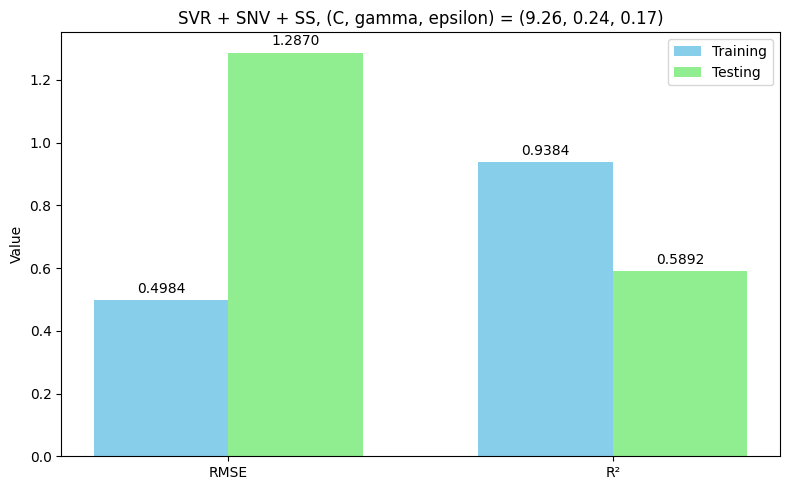

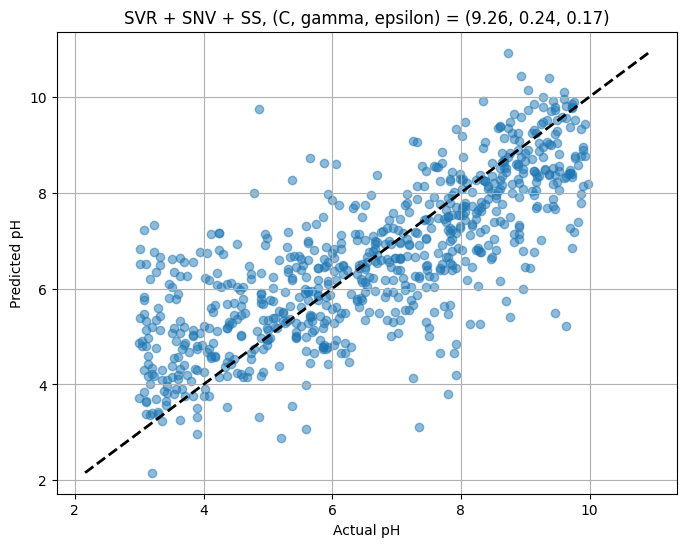

In [ ]:
C, gamma, epsilon = svr_training.loc[svr_training['Method'] == "SVR + SNV + SS"
                                    , ['Best_C', 'Best_gamma', 'Best_epsilon']].iloc[-1]
svr_snv_ss = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(X_train_snv_ss, y_train)
metrics_calculation(svr_snv_ss, X_train_snv_ss, y_train, X_test_snv_ss, y_test,
                    f'SVR + SNV + SS, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',
                    f'SVR + SNV + SS, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',0, 1)

##### **SVR + MSC + SS**

In [ ]:
msc_ss = StandardScaler()
X_train_msc_ss = msc_ss.fit_transform(X_train_msc)
X_test_msc_ss = msc_ss.transform(X_test_msc)

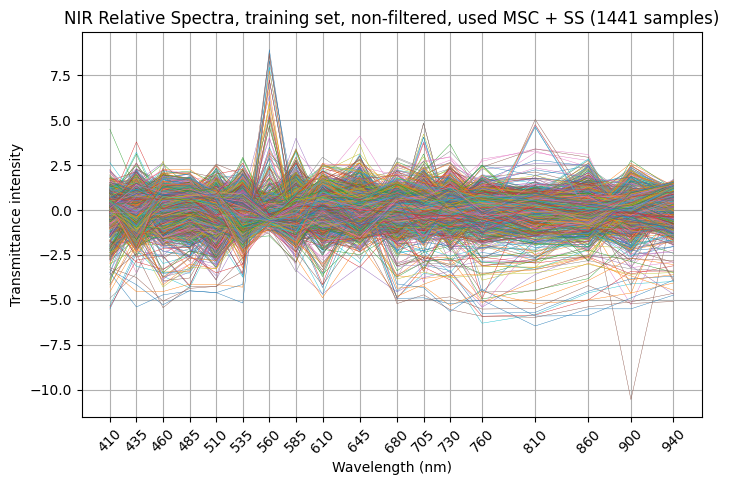

In [ ]:
spectra_plot (pd.DataFrame(X_train_msc_ss, columns=wavelengths),
              'NIR Relative Spectra, training set, non-filtered, used MSC + SS', 0)

In [ ]:
pbounds = {
    'log_C': (0, 3.0),
    'log_gamma': (-3.0, 1.0),
    'epsilon': (0.001, 1.0)
}

def objective_wrapper (log_C, log_gamma, epsilon):
  return svr_val_evaluate(X_train_msc_ss, X_test_msc_ss, y_train, y_test, log_C, log_gamma, epsilon)

optimizer = BayesianOptimization(f=objective_wrapper, pbounds=pbounds,
                                 random_state=42, verbose=2)
optimizer.maximize(init_points=5, n_iter=200)

print(f"Best params: {optimizer.max['params']}")
p, target = optimizer.max['params'], optimizer.max['target']
svr_training.loc[len(svr_training)] = ['SVR + MSC + SS', target, 10**p['log_C'], 10**p['log_gamma'], p['epsilon']]

|   iter    |  target   |   log_C   | log_gamma |  epsilon  |
-------------------------------------------------------------
| 1         | -3.915743 | 1.1236203 | 0.8028572 | 0.7322619 |
| 2         | -2.471059 | 1.7959754 | -2.375925 | 0.1568385 |
| 3         | -3.614776 | 0.1742508 | 0.4647045 | 0.6015138 |
| 4         | -2.709040 | 2.1242177 | -2.917662 | 0.9699399 |
| 5         | -2.074633 | 2.4973279 | -2.150643 | 0.1826431 |
| 6         | -2.907794 | 3.0       | -0.977514 | 0.001     |
| 7         | -2.592965 | 3.0       | -3.0      | 0.001     |
| 8         | -2.383758 | 3.0       | -1.936443 | 1.0       |
| 9         | -3.444792 | 0.0       | -3.0      | 1.0       |
| 10        | -2.045706 | 2.0041639 | -1.574554 | 1.0       |
| 11        | -1.824710 | 1.6695834 | -1.321934 | 0.001     |
| 12        | -1.943813 | 0.6891656 | -1.308444 | 0.001     |
| 13        | -1.932963 | 0.9975302 | -1.248566 | 0.9521041 |
| 14        | -1.649471 | 1.3339258 | -0.916203 | 0.3952732 |
| 15    

In [ ]:
svr_training

,Method,Validation -MSE,Best_C,Best_gamma,Best_epsilon
0,SVR + SNV + MSC,-1.764501,1000.000000,10.000000,0.908557
1,SVR + SNV + SS,-1.302129,13.814337,0.286202,0.444204
2,SVR + MSC + SS,-1.298329,13.672852,0.291585,0.439947
3,SVR + SNV + MSC + SS,-1.298302,13.749482,0.290728,0.440252
4,SVR + raw data,-1.692258,616.496870,10.000000,0.541995
5,SVR + SNV,-1.884651,17.343116,10.000000,0.001000
6,SVR + MSC,-2.044781,1000.000000,10.000000,1.000000
7,SVR + SS,-1.632293,31.234211,0.134872,0.485393
8,SVR + SNV + SS,-1.656357,9.257217,0.243200,0.165935
9,SVR + MSC + SS,-1.576957,8.308608,0.220369,0.117070


--- SVR + MSC + SS, (C, gamma, epsilon) = (8.31, 0.22, 0.12) ---
Training RMSE: 0.4976
Testing RMSE: 1.2558
Training R²: 0.9386
Testing R²: 0.6089


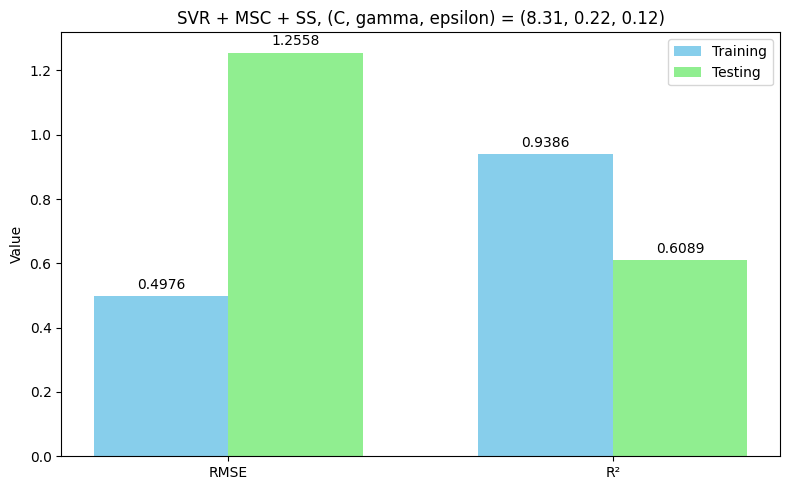

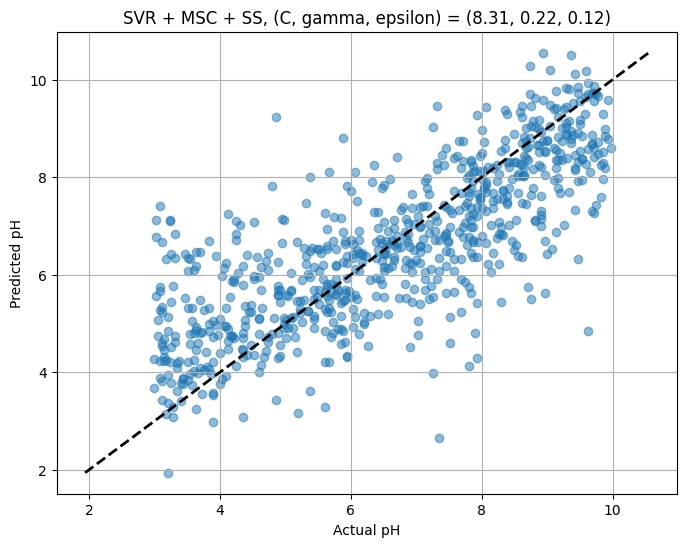

In [ ]:
C, gamma, epsilon = svr_training.loc[svr_training['Method'] == "SVR + MSC + SS"
                                    ,['Best_C', 'Best_gamma', 'Best_epsilon']].iloc[-1]
svr_msc_ss = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(X_train_msc_ss, y_train)
metrics_calculation(svr_msc_ss, X_train_msc_ss, y_train, X_test_msc_ss, y_test,
                    f'SVR + MSC + SS, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',
                    f'SVR + MSC + SS, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})', 0, 1)

##### **SVR + MM**

In [ ]:
pbounds = {
    'log_C': (0, 3.0),
    'log_gamma': (-3.0, 1.0),
    'epsilon': (0.001, 1.0)
}

def objective_wrapper (log_C, log_gamma, epsilon):
  return svr_val_evaluate(X_train_mm, X_val_mm, y_train, y_val, log_C, log_gamma, epsilon)

optimizer = BayesianOptimization(f=objective_wrapper, pbounds=pbounds,
                                 random_state=42, verbose=2)
optimizer.maximize(init_points=5, n_iter=200)

print(f"Best params: {optimizer.max['params']}")
p, target = optimizer.max['params'], optimizer.max['target']
svr_training.loc[len(svr_training)] = ['SVR + MinMax', target, 10**p['log_C'], 10**p['log_gamma'], p['epsilon']]

|   iter    |  target   |   log_C   | log_gamma |  epsilon  |
-------------------------------------------------------------
| 1         | -1.500034 | 1.1236203 | 0.8028572 | 0.7322619 |
| 2         | -3.134435 | 1.7959754 | -2.375925 | 0.1568385 |
| 3         | -1.606716 | 0.1742508 | 0.4647045 | 0.6015138 |
| 4         | -3.244998 | 2.1242177 | -2.917662 | 0.9699399 |
| 5         | -2.792762 | 2.4973279 | -2.150643 | 0.1826431 |
| 6         | -1.557144 | 3.0       | 1.0       | 0.001     |
| 7         | -1.697588 | 0.0       | 1.0       | 0.001     |
| 8         | -1.681540 | 3.0       | 1.0       | 1.0       |
| 9         | -1.926505 | 0.0       | 1.0       | 1.0       |
| 10        | -1.534244 | 1.7439807 | 0.1296985 | 0.001     |
| 11        | -1.495979 | 1.6504641 | 1.0       | 0.001     |
| 12        | -2.687290 | 0.0       | -0.472905 | 0.001     |
| 13        | -1.479623 | 3.0       | -0.333652 | 1.0       |
| 14        | -1.938180 | 3.0       | -0.211865 | 0.001     |
| 15    

In [ ]:
svr_training

,Method,Validation -MSE,Best_C,Best_gamma,Best_epsilon
0,SVR + raw normalized data,-1.218895,23.015294,0.001585,0.413544
1,SVR + SS + PCA_4,-2.094891,7.172396,0.150601,0.573946
2,SVR + SS + PCA_8,-1.591236,14.027896,0.119645,0.591784
3,SVR + SS + PCA_10,-1.475780,34.942988,0.088083,0.555575
4,SVR + SS + PCA_14,-1.373023,45.404255,0.081665,0.490364
5,SVR + SNV,-2.158349,1000.000000,10.000000,0.666542
6,SVR + MSC,-1.616367,74.552722,0.005577,0.152675
7,SVR + SS,-1.355955,13.482497,0.154879,0.183675
8,SVR + SNV + SS,-1.415809,13.444704,0.110319,0.464233
9,SVR + MSC + SS,-1.409964,12.725321,0.113022,0.458896


--- SVR + MinMax, (C, gamma, epsilon) = (13.02, 4.73, 0.18) ---
Training RMSE: 0.6316
Testing RMSE: 1.1902
Training R²: 0.9012
Testing R²: 0.6485


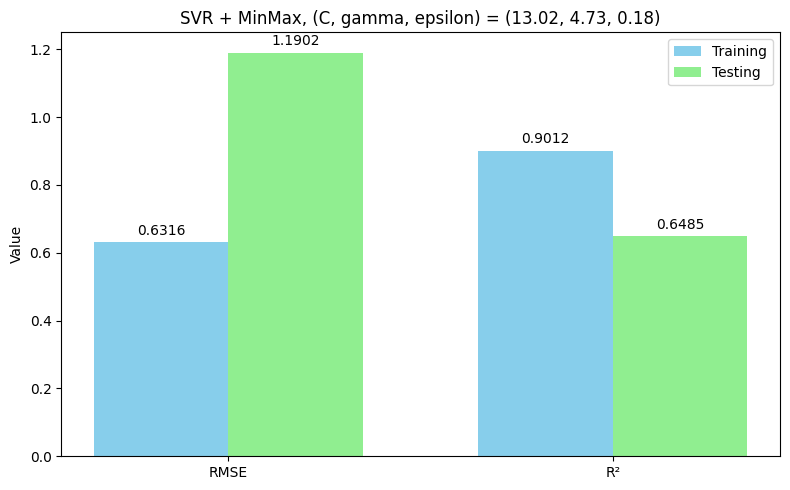

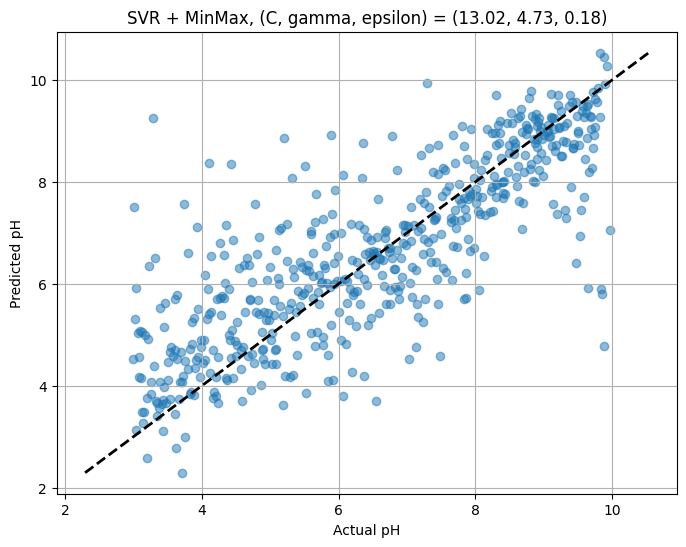

In [ ]:
X_train_val_mm = np.vstack((X_train_mm, X_val_mm))
C, gamma, epsilon = svr_training.loc[svr_training['Method'] == "SVR + MinMax"
                                    , ['Best_C', 'Best_gamma', 'Best_epsilon']].iloc[-1]
svr_mm = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(X_train_val_mm, y_train_val)
metrics_calculation(svr_mm, X_train_val_mm, y_train_val, X_test_mm, y_test,
                    f'SVR + MinMax, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',
                    f'SVR + MinMax, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})', 0, 1)

##### **SVR + SNV + MM**

In [ ]:
snv_mm = MinMaxScaler()
X_train_snv_mm = snv_mm.fit_transform(X_train_snv)
X_val_snv_mm = snv_mm.transform(X_val_snv)
X_test_snv_mm = snv_mm.transform(X_test_snv)

In [ ]:
pbounds = {
    'log_C': (0, 3.0),
    'log_gamma': (-3.0, 1.0),
    'epsilon': (0.001, 1.0)
}

def objective_wrapper (log_C, log_gamma, epsilon):
  return svr_val_evaluate(X_train_snv_mm, X_val_snv_mm, y_train, y_val, log_C, log_gamma, epsilon)

optimizer = BayesianOptimization(f=objective_wrapper, pbounds=pbounds,
                                 random_state=42, verbose=2)
optimizer.maximize(init_points=5, n_iter=200)

print(f"Best params: {optimizer.max['params']}")
p, target = optimizer.max['params'], optimizer.max['target']
svr_training.loc[len(svr_training)] = ['SVR + SNV + MinMax', target, 10**p['log_C'], 10**p['log_gamma'], p['epsilon']]

|   iter    |  target   |   log_C   | log_gamma |  epsilon  |
-------------------------------------------------------------
| 1         | -1.447318 | 1.1236203 | 0.8028572 | 0.7322619 |
| 2         | -3.194769 | 1.7959754 | -2.375925 | 0.1568385 |
| 3         | -1.703074 | 0.1742508 | 0.4647045 | 0.6015138 |
| 4         | -3.254227 | 2.1242177 | -2.917662 | 0.9699399 |
| 5         | -2.761438 | 2.4973279 | -2.150643 | 0.1826431 |
| 6         | -1.786051 | 3.0       | 1.0       | 0.001     |
| 7         | -2.036717 | 3.0       | 0.0590943 | 1.0       |
| 8         | -1.431312 | 0.9359485 | 1.0       | 0.001     |
| 9         | -1.771351 | 0.0       | 1.0       | 1.0       |
| 10        | -1.551423 | 1.6936191 | 0.3419219 | 0.001     |
| 11        | -1.643319 | 1.9579982 | 1.0       | 1.0       |
| 12        | -1.484046 | 1.6431883 | 1.0       | 0.001     |
| 13        | -1.428183 | 1.1270860 | 1.0       | 0.4002262 |
| 14        | -1.494793 | 1.0441322 | 0.5901781 | 0.001     |
| 15    

In [ ]:
svr_training

,Method,Validation -MSE,Best_C,Best_gamma,Best_epsilon
0,SVR + raw normalized data,-1.218895,23.015294,0.001585,0.413544
1,SVR + SS + PCA_4,-2.094891,7.172396,0.150601,0.573946
2,SVR + SS + PCA_8,-1.591236,14.027896,0.119645,0.591784
3,SVR + SS + PCA_10,-1.475780,34.942988,0.088083,0.555575
4,SVR + SS + PCA_14,-1.373023,45.404255,0.081665,0.490364
5,SVR + SNV,-2.158349,1000.000000,10.000000,0.666542
6,SVR + MSC,-1.616367,74.552722,0.005577,0.152675
7,SVR + SS,-1.355955,13.482497,0.154879,0.183675
8,SVR + SNV + SS,-1.415809,13.444704,0.110319,0.464233
9,SVR + MSC + SS,-1.409964,12.725321,0.113022,0.458896


--- SVR + SNV + MinMax, (C, gamma, epsilon) = (28.43, 10.00, 0.26) ---
Training RMSE: 0.4236
Testing RMSE: 1.2937
Training R²: 0.9555
Testing R²: 0.5847


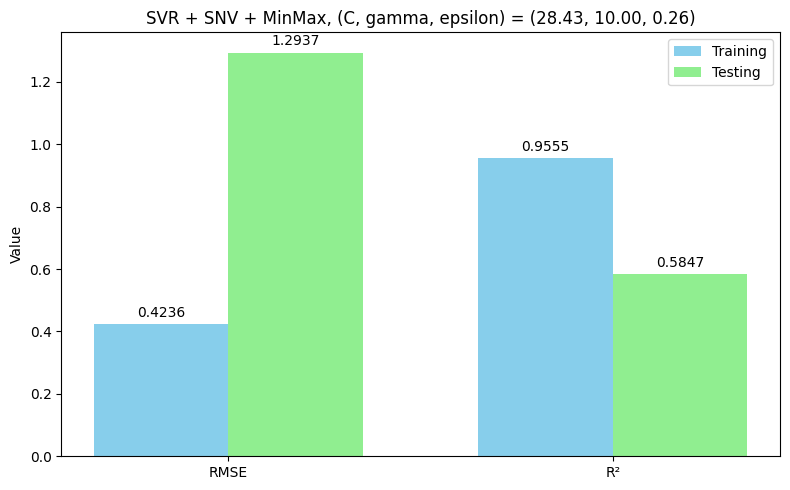

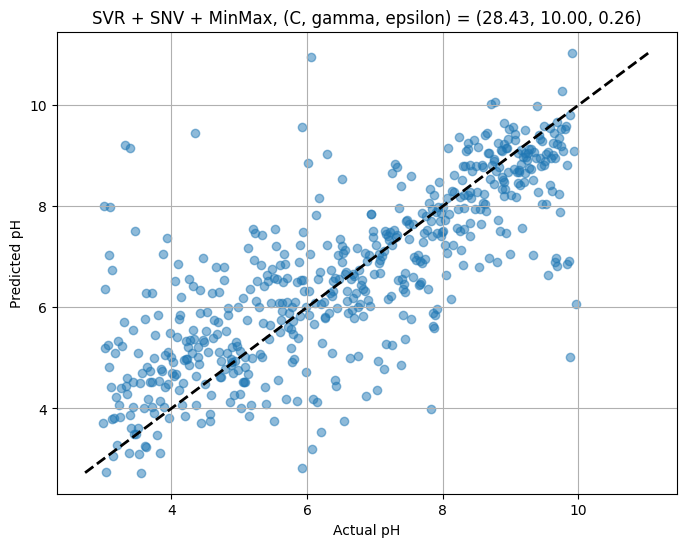

In [ ]:
X_train_val_snv_mm = np.vstack((X_train_snv_mm, X_val_snv_mm))
C, gamma, epsilon = svr_training.loc[svr_training['Method'] == "SVR + SNV + MinMax"
                                    , ['Best_C', 'Best_gamma', 'Best_epsilon']].iloc[-1]
svr_snv_mm = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(X_train_val_snv_mm, y_train_val)
metrics_calculation(svr_snv_mm, X_train_val_snv_mm, y_train_val, X_test_snv_mm, y_test,
                    f'SVR + SNV + MinMax, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',
                    f'SVR + SNV + MinMax, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',0, 1)

##### **SVR + MSC + MM**

In [ ]:
msc_mm = MinMaxScaler()
X_train_msc_mm = msc_mm.fit_transform(X_train_msc)
X_val_msc_mm = msc_mm.transform(X_val_msc)
X_test_msc_mm = msc_mm.transform(X_test_msc)

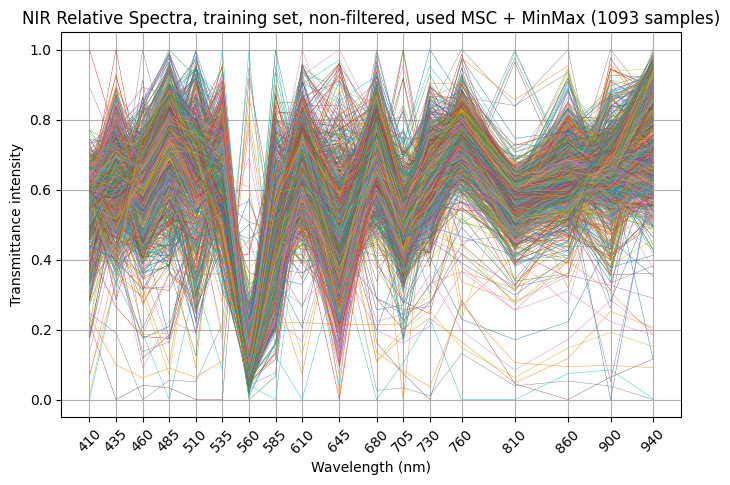

In [ ]:
spectra_plot (pd.DataFrame(X_train_msc_mm, columns=wavelengths),
              'NIR Relative Spectra, training set, non-filtered, used MSC + MinMax', 0)

In [ ]:
pbounds = {
    'log_C': (0, 3.0),
    'log_gamma': (-3.0, 1.0),
    'epsilon': (0.001, 1.0)
}

def objective_wrapper (log_C, log_gamma, epsilon):
  return svr_val_evaluate(X_train_msc_mm, X_val_msc_mm, y_train, y_val, log_C, log_gamma, epsilon)

optimizer = BayesianOptimization(f=objective_wrapper, pbounds=pbounds,
                                 random_state=42, verbose=2)
optimizer.maximize(init_points=5, n_iter=200)

print(f"Best params: {optimizer.max['params']}")
p, target = optimizer.max['params'], optimizer.max['target']
svr_training.loc[len(svr_training)] = ['SVR + MSC + MinMax', target, 10**p['log_C'], 10**p['log_gamma'], p['epsilon']]

|   iter    |  target   |   log_C   | log_gamma |  epsilon  |
-------------------------------------------------------------
| 1         | -1.755850 | 1.1236203 | 0.8028572 | 0.7322619 |
| 2         | -3.220894 | 1.7959754 | -2.375925 | 0.1568385 |
| 3         | -2.202072 | 0.1742508 | 0.4647045 | 0.6015138 |
| 4         | -3.248552 | 2.1242177 | -2.917662 | 0.9699399 |
| 5         | -3.125992 | 2.4973279 | -2.150643 | 0.1826431 |
| 6         | -2.019322 | 3.0       | 1.0       | 1.0       |
| 7         | -2.023264 | 1.8817029 | 1.0       | 0.001     |
| 8         | -1.979929 | 1.7767001 | 0.1736966 | 1.0       |
| 9         | -1.860622 | 1.6269718 | 1.0       | 1.0       |
| 10        | -1.677032 | 0.7202254 | 1.0       | 0.001     |
| 11        | -1.914859 | 1.0357714 | 0.2999999 | 0.001     |
| 12        | -2.242540 | 3.0       | -0.188803 | 1.0       |
| 13        | -1.672552 | 1.0509627 | 1.0       | 0.2549584 |
| 14        | -1.852203 | 0.7473347 | 1.0       | 1.0       |
| 15    

In [ ]:
svr_training

,Method,Validation -MSE,Best_C,Best_gamma,Best_epsilon
0,SVR + MSC + SS,-1.652283,6.938526,0.133665,0.181408
1,SVR + MSC + MinMax,-1.648354,7.359055,9.631313,0.294120


--- SVR + MSC + MinMax, (C, gamma, epsilon) = (7.36, 9.63, 0.29) ---
Training RMSE: 0.752
Testing RMSE: 1.2573
Training R²: 0.8599
Testing R²: 0.6077


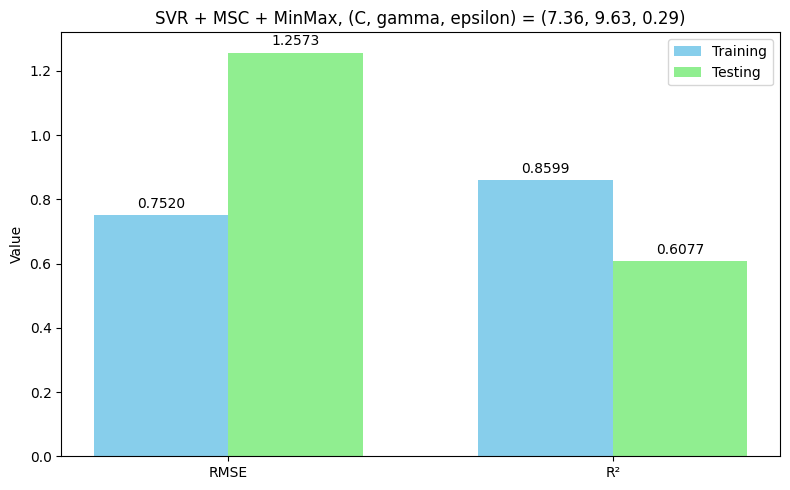

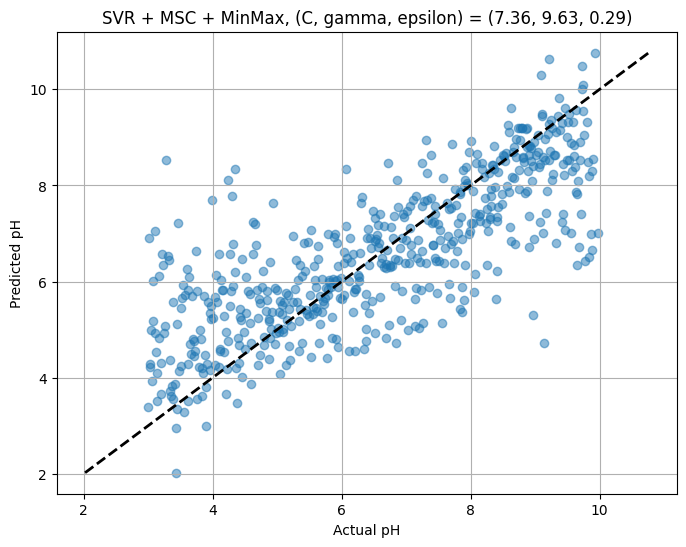

In [ ]:
X_train_val_msc_mm = np.vstack((X_train_msc_mm, X_val_msc_mm))
C, gamma, epsilon = svr_training.loc[svr_training['Method'] == "SVR + MSC + MinMax"
                                    , ['Best_C', 'Best_gamma', 'Best_epsilon']].iloc[-1]
svr_msc_mm = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(X_train_val_msc_mm, y_train_val)
metrics_calculation(svr_msc_mm, X_train_val_msc_mm, y_train_val, X_test_msc_mm, y_test,
                    f'SVR + MSC + MinMax, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',
                    f'SVR + MSC + MinMax, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',0, 1)

##### **SVR + RS**

In [ ]:
pbounds = {
    'log_C': (0, 3.0),
    'log_gamma': (-3.0, 1.0),
    'epsilon': (0.001, 1.0)
}

def objective_wrapper (log_C, log_gamma, epsilon):
  return svr_val_evaluate(X_train_rs, X_val_rs, y_train, y_val, log_C, log_gamma, epsilon)

optimizer = BayesianOptimization(f=objective_wrapper, pbounds=pbounds,
                                 random_state=42, verbose=2)
optimizer.maximize(init_points=5, n_iter=200)

print(f"Best params: {optimizer.max['params']}")
p, target = optimizer.max['params'], optimizer.max['target']
svr_training.loc[len(svr_training)] = ['SVR + RS', target, 10**p['log_C'], 10**p['log_gamma'], p['epsilon']]

|   iter    |  target   |   log_C   | log_gamma |  epsilon  |
-------------------------------------------------------------
| 1         | -3.686713 | 1.1236203 | 0.8028572 | 0.7322619 |
| 2         | -2.073319 | 1.7959754 | -2.375925 | 0.1568385 |
| 3         | -3.057460 | 0.1742508 | 0.4647045 | 0.6015138 |
| 4         | -2.364761 | 2.1242177 | -2.917662 | 0.9699399 |
| 5         | -1.779118 | 2.4973279 | -2.150643 | 0.1826431 |
| 6         | -2.547894 | 3.0       | -0.993564 | 0.001     |
| 7         | -2.178555 | 3.0       | -3.0      | 0.001     |
| 8         | -3.515517 | 0.0       | -3.0      | 0.001     |
| 9         | -1.669065 | 3.0       | -1.936286 | 1.0       |
| 10        | -1.554480 | 2.0427528 | -1.528623 | 1.0       |
| 11        | -1.671014 | 0.9470394 | -1.415510 | 1.0       |
| 12        | -1.495162 | 1.2849702 | -1.214252 | 0.001     |
| 13        | -1.776975 | 0.0       | -1.040149 | 0.001     |
| 14        | -1.874485 | 0.0       | -1.107859 | 1.0       |
| 15    

In [ ]:
svr_training

,Method,Validation -MSE,Best_C,Best_gamma,Best_epsilon
0,SVR + raw normalized data,-1.218895,23.015294,0.001585,0.413544
1,SVR + SS + PCA_4,-2.094891,7.172396,0.150601,0.573946
2,SVR + SS + PCA_8,-1.591236,14.027896,0.119645,0.591784
3,SVR + SS + PCA_10,-1.475780,34.942988,0.088083,0.555575
4,SVR + SS + PCA_14,-1.373023,45.404255,0.081665,0.490364
5,SVR + SNV,-2.158349,1000.000000,10.000000,0.666542
6,SVR + MSC,-1.616367,74.552722,0.005577,0.152675
7,SVR + SS,-1.355955,13.482497,0.154879,0.183675
8,SVR + SNV + SS,-1.415809,13.444704,0.110319,0.464233
9,SVR + MSC + SS,-1.409964,12.725321,0.113022,0.458896


--- SVR + RS, (C, gamma, epsilon) = (22.39, 0.17, 0.29) ---
Training RMSE: 0.6589
Testing RMSE: 1.1847
Training R²: 0.8924
Testing R²: 0.6517


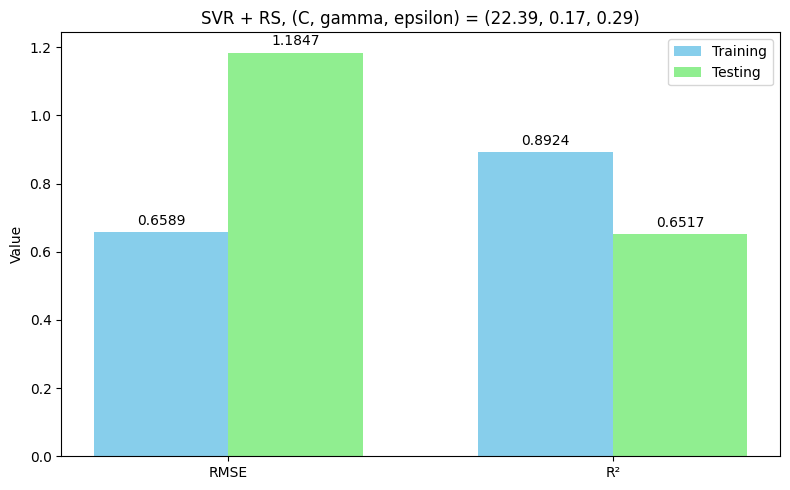

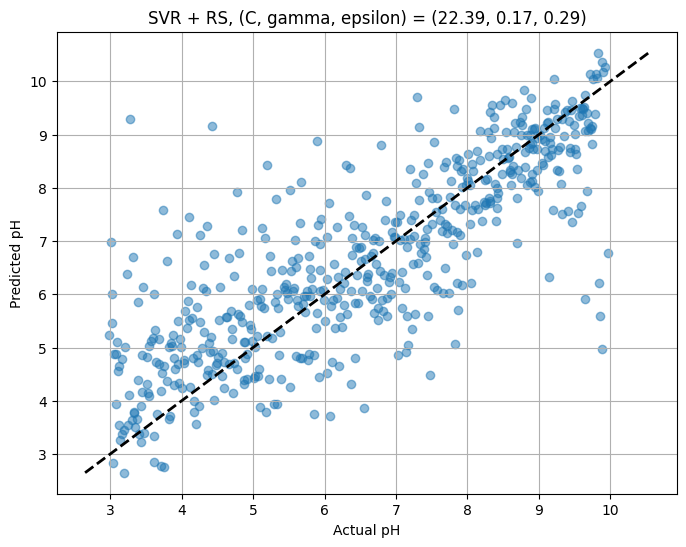

In [ ]:
X_train_val_rs = np.vstack((X_train_rs, X_val_rs))
C, gamma, epsilon = svr_training.loc[svr_training['Method'] == "SVR + RS"
                                    , ['Best_C', 'Best_gamma', 'Best_epsilon']].iloc[-1]
svr_rs = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(X_train_val_rs, y_train_val)
metrics_calculation(svr_rs, X_train_val_rs, y_train_val, X_test_rs, y_test,
                    f'SVR + RS, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',
                    f'SVR + RS, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',0, 1)

##### **SVR + SNV + RS**

In [ ]:
snv_rs = RobustScaler()
X_train_snv_rs = snv_rs.fit_transform(X_train_snv)
X_val_snv_rs = snv_rs.transform(X_val_snv)
X_test_snv_rs = snv_rs.transform(X_test_snv)

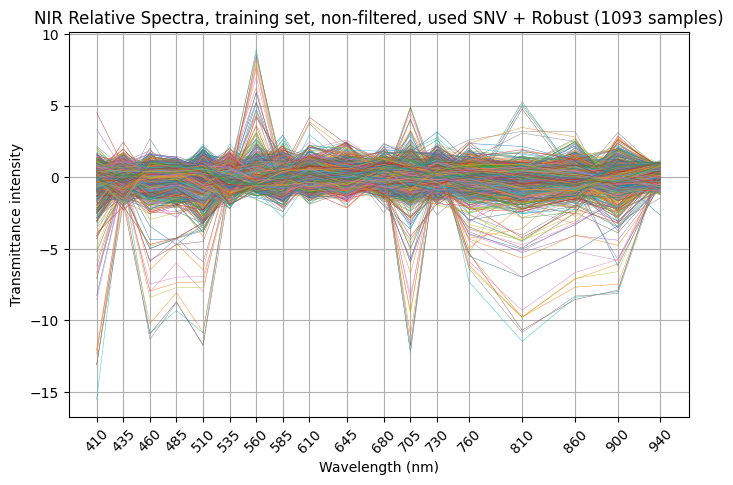

In [ ]:
spectra_plot (pd.DataFrame(X_train_snv_rs, columns=wavelengths),
              'NIR Relative Spectra, training set, non-filtered, used SNV + Robust', 0)

In [ ]:
pbounds = {
    'log_C': (0, 3.0),
    'log_gamma': (-3.0, 1.0),
    'epsilon': (0.001, 1.0)
}

def objective_wrapper (log_C, log_gamma, epsilon):
  return svr_val_evaluate(X_train_snv_rs, X_val_snv_rs, y_train, y_val, log_C, log_gamma, epsilon)

optimizer = BayesianOptimization(f=objective_wrapper, pbounds=pbounds,
                                 random_state=42, verbose=2)
optimizer.maximize(init_points=5, n_iter=200)

print(f"Best params: {optimizer.max['params']}")
p, target = optimizer.max['params'], optimizer.max['target']
svr_training.loc[len(svr_training)] = ['SVR + SNV + RobustScaler', target, 10**p['log_C'], 10**p['log_gamma'], p['epsilon']]

|   iter    |  target   |   log_C   | log_gamma |  epsilon  |
-------------------------------------------------------------
| 1         | -3.954718 | 1.1236203 | 0.8028572 | 0.7322619 |
| 2         | -2.480079 | 1.7959754 | -2.375925 | 0.1568385 |
| 3         | -3.643668 | 0.1742508 | 0.4647045 | 0.6015138 |
| 4         | -2.651132 | 2.1242177 | -2.917662 | 0.9699399 |
| 5         | -2.072681 | 2.4973279 | -2.150643 | 0.1826431 |
| 6         | -3.147006 | 3.0       | -0.965969 | 0.001     |
| 7         | -2.660476 | 3.0       | -3.0      | 0.001     |
| 8         | -2.243066 | 3.0       | -2.036204 | 1.0       |
| 9         | -3.539692 | 0.0       | -3.0      | 1.0       |
| 10        | -1.926223 | 2.0779355 | -1.648547 | 1.0       |
| 11        | -1.925587 | 1.1988063 | -1.366380 | 1.0       |
| 12        | -1.767512 | 1.2535551 | -1.233215 | 0.001     |
| 13        | -2.273697 | 0.1746013 | -1.331959 | 0.001     |
| 14        | -1.794824 | 1.6955823 | -1.029747 | 0.5502078 |
| 15    

In [ ]:
svr_training

,Method,Validation -MSE,Best_C,Best_gamma,Best_epsilon
0,SVR + MSC + SS,-1.652283,6.938526,0.133665,0.181408
1,SVR + MSC + MinMax,-1.648354,7.359055,9.631313,0.294120
2,SVR + SNV + RobustScaler,-1.648529,6.723687,0.185552,0.222104
3,SVR + MSC + RobustScaler,-1.649141,6.221975,0.192149,0.211310


--- SVR + SNV + RobustScaler, (C, gamma, epsilon) = (6.72, 0.19, 0.22) ---
Training RMSE: 0.7125
Testing RMSE: 1.2376
Training R²: 0.8742
Testing R²: 0.6199


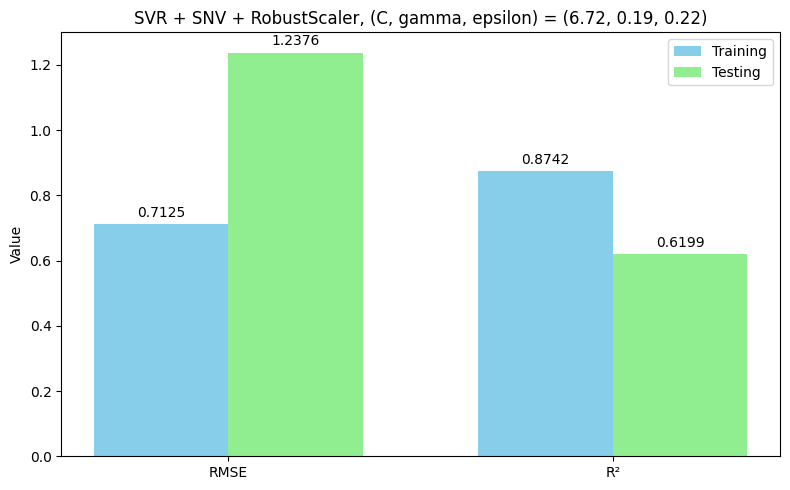

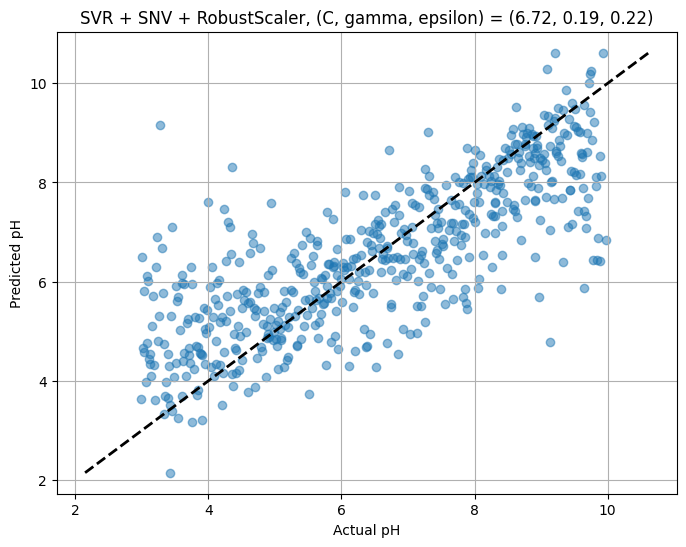

In [ ]:
X_train_val_snv_rs = np.vstack((X_train_snv_rs, X_val_snv_rs))
C, gamma, epsilon = svr_training.loc[svr_training['Method'] == "SVR + SNV + RobustScaler"
                                    , ['Best_C', 'Best_gamma', 'Best_epsilon']].iloc[-1]
svr_snv_rs = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(X_train_val_snv_rs, y_train_val)
metrics_calculation(svr_snv_rs, X_train_val_snv_rs, y_train_val, X_test_snv_rs, y_test,
                    f'SVR + SNV + RobustScaler, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',
                    f'SVR + SNV + RobustScaler, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',0, 1)

##### **SVR + MSC + RS**

In [ ]:
msc_rs = RobustScaler()
X_train_msc_rs = msc_rs.fit_transform(X_train_msc)
X_val_msc_rs = msc_rs.transform(X_val_msc)
X_test_msc_rs = msc_rs.transform(X_test_msc)

In [ ]:
#spectra_plot (pd.DataFrame(X_train_msc_rs, columns=wavelengths),
              #'NIR Relative Spectra, training set, non-filtered, used MSC + Robust', 0)

In [ ]:
pbounds = {
    'log_C': (0, 3.0),
    'log_gamma': (-3.0, 1.0),
    'epsilon': (0.001, 1.0)
}

def objective_wrapper (log_C, log_gamma, epsilon):
  return svr_val_evaluate(X_train_msc_rs, X_val_msc_rs, y_train, y_val, log_C, log_gamma, epsilon)

optimizer = BayesianOptimization(f=objective_wrapper, pbounds=pbounds,
                                 random_state=42, verbose=2)
optimizer.maximize(init_points=5, n_iter=200)

print(f"Best params: {optimizer.max['params']}")
p, target = optimizer.max['params'], optimizer.max['target']
svr_training.loc[len(svr_training)] = ['SVR + MSC + RobustScaler', target, 10**p['log_C'], 10**p['log_gamma'], p['epsilon']]

|   iter    |  target   |   log_C   | log_gamma |  epsilon  |
-------------------------------------------------------------
| 1         | -3.956272 | 1.1236203 | 0.8028572 | 0.7322619 |
| 2         | -2.536647 | 1.7959754 | -2.375925 | 0.1568385 |
| 3         | -3.647901 | 0.1742508 | 0.4647045 | 0.6015138 |
| 4         | -2.674051 | 2.1242177 | -2.917662 | 0.9699399 |
| 5         | -2.065619 | 2.4973279 | -2.150643 | 0.1826431 |
| 6         | -3.353341 | 3.0       | -1.000765 | 0.001     |
| 7         | -2.667080 | 3.0       | -2.931730 | 0.001     |
| 8         | -2.124269 | 2.9491949 | -2.099080 | 1.0       |
| 9         | -1.912684 | 2.0750227 | -1.661200 | 1.0       |
| 10        | -3.027959 | 0.0       | -2.160991 | 1.0       |
| 11        | -1.886640 | 1.3211849 | -1.286845 | 1.0       |
| 12        | -1.771933 | 1.2513881 | -1.228177 | 0.001     |
| 13        | -2.055318 | 0.3764258 | -1.214017 | 0.001     |
| 14        | -1.832161 | 1.7298689 | -0.960892 | 0.5509894 |
| 15    

In [ ]:
svr_training.to_excel('svr_training_results.xlsx', index=False)
svr_training

,Method,Validation -MSE,Best_C,Best_gamma,Best_epsilon
0,SVR + MSC + SS,-1.652283,6.938526,0.133665,0.181408
1,SVR + MSC + MinMax,-1.648354,7.359055,9.631313,0.294120
2,SVR + SNV + RobustScaler,-1.648529,6.723687,0.185552,0.222104
3,SVR + MSC + RobustScaler,-1.649141,6.221975,0.192149,0.211310


--- SVR + MSC + RobustScaler, (C, gamma, epsilon) = (6.22, 0.19, 0.21) ---
Training RMSE: 0.7112
Testing RMSE: 1.2287
Training R²: 0.8747
Testing R²: 0.6254


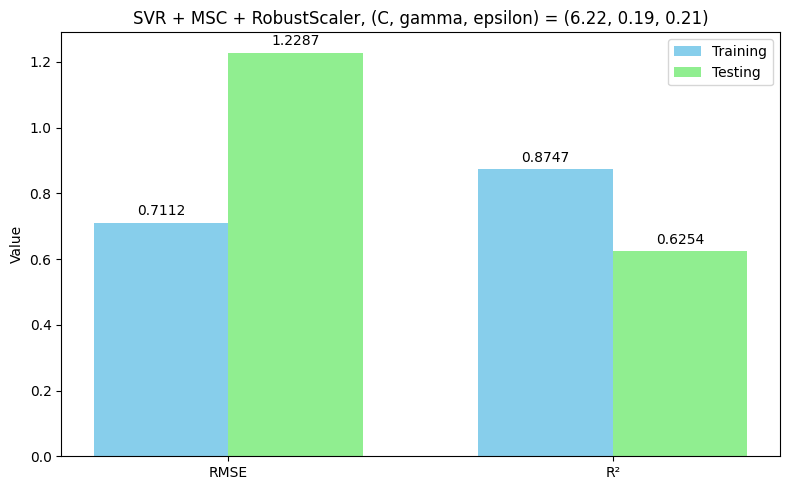

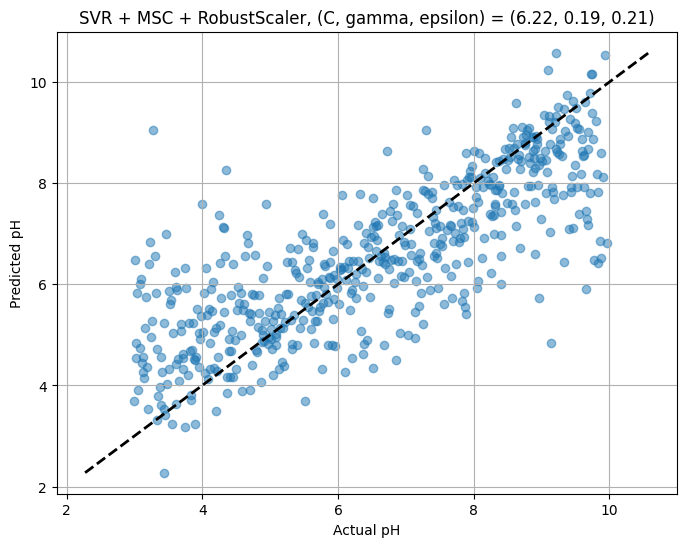

In [ ]:
X_train_val_msc_rs = np.vstack((X_train_msc_rs, X_val_msc_rs))
C, gamma, epsilon = svr_training.loc[svr_training['Method'] == "SVR + MSC + RobustScaler"
                                    , ['Best_C', 'Best_gamma', 'Best_epsilon']].iloc[-1]
svr_msc_rs = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(X_train_val_msc_rs, y_train_val)
metrics_calculation(svr_msc_rs, X_train_val_msc_rs, y_train_val, X_test_msc_rs, y_test,
                    f'SVR + MSC + RobustScaler, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',
                    f'SVR + MSC + RobustScaler, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',0, 1)

##### **SVR + SS + SNV**

In [ ]:
ss_snv = StandardNormalVariate()
X_train_ss_snv = ss_snv.fit_transform(X_train_ss)
X_val_ss_snv = ss_snv.transform(X_val_ss)
X_test_ss_snv = ss_snv.transform(X_test_ss)

In [ ]:
pbounds = {
    'log_C': (0, 3.0),       # C: 10^-2 = 0.01 đến 10^3 = 1000
    'log_gamma': (-3.0, 1.0),   # gamma: 10^-4 = 0.0001 đến 10^1 = 10
    'epsilon': (0.001, 1.0)     # epsilon: 0.001 đến 1.0
}

def objective_wrapper (log_C, log_gamma, epsilon):
  return svr_val_evaluate(X_train_ss_snv, X_val_ss_snv, y_train, y_val, log_C, log_gamma, epsilon)

optimizer = BayesianOptimization(f=objective_wrapper, pbounds=pbounds,
                                 random_state=42, verbose=2)
optimizer.maximize(init_points=5, n_iter=200)

print(f"Best params: {optimizer.max['params']}")
p, target = optimizer.max['params'], optimizer.max['target']
svr_training.loc[len(svr_training)] = ['SVR + SS + SNV', target, 10**p['log_C'], 10**p['log_gamma'], p['epsilon']]

|   iter    |  target   |   log_C   | log_gamma |  epsilon  |
-------------------------------------------------------------
| 1         | -3.976357 | 1.1236203 | 0.8028572 | 0.7322619 |
| 2         | -2.328871 | 1.7959754 | -2.375925 | 0.1568385 |
| 3         | -3.840046 | 0.1742508 | 0.4647045 | 0.6015138 |
| 4         | -2.600840 | 2.1242177 | -2.917662 | 0.9699399 |
| 5         | -1.950732 | 2.4973279 | -2.150643 | 0.1826431 |
| 6         | -1.822327 | 3.0       | -0.892716 | 0.001     |
| 7         | -2.341324 | 3.0       | -3.0      | 0.001     |
| 8         | -1.968715 | 3.0       | -1.308229 | 1.0       |
| 9         | -2.712026 | 3.0       | -1.650843 | 0.001     |
| 10        | -2.442776 | 3.0       | -0.234813 | 0.6198804 |
| 11        | -1.748476 | 2.1221678 | -1.187847 | 0.5275297 |
| 12        | -1.642115 | 2.1936539 | -0.618286 | 0.001     |
| 13        | -1.769634 | 1.3068304 | -1.175562 | 0.001     |
| 14        | -2.877605 | 0.0       | -1.945742 | 0.001     |
| 15    

In [ ]:
svr_training

,Method,Validation -MSE,Best_C,Best_gamma,Best_epsilon
0,SVR + raw normalized data,-1.779268,952.966849,10.000000,0.947996
1,SVR + SS,-1.687487,20.110275,0.133629,0.556200
2,SVR + SNV + SS,-1.581642,18.109583,0.154516,0.122393
3,SVR + MSC + SS,-1.587150,19.926159,0.163333,0.265538
4,SVR + SS + SNV,-1.539207,12.814444,0.127819,0.515994


--- SVR + SS + SNV, (C, gamma, epsilon) = (12.81, 0.13, 0.52) ---
Testing RMSE: 1.1975
Training RMSE: 0.5279
Testing R²: 0.6436
Training R²: 0.9309


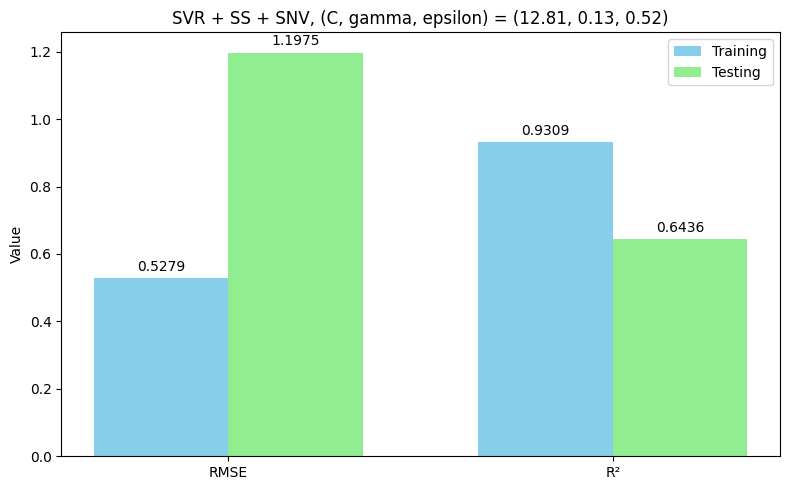

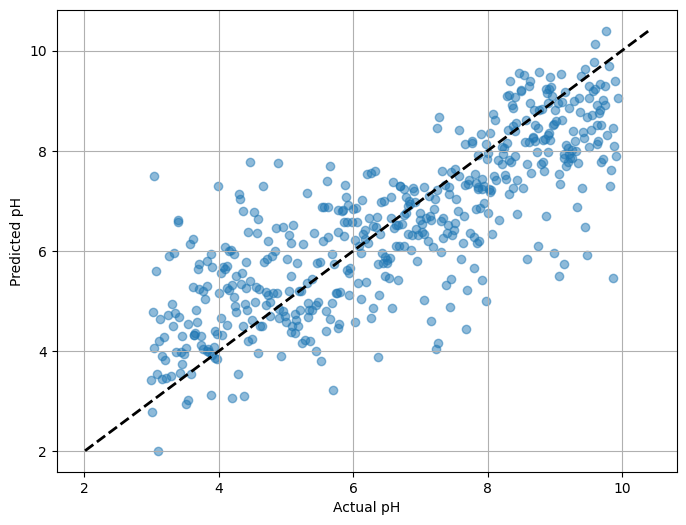

In [ ]:
X_train_val_ss_snv = np.vstack((X_train_ss_snv, X_val_ss_snv))
C, gamma, epsilon = svr_training.loc[svr_training['Method'] == "SVR + SS + SNV"
                                    , ['Best_C', 'Best_gamma', 'Best_epsilon']].iloc[0]
svr_ss_snv = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(X_train_val_ss_snv, y_train_val)
metrics_calculation(svr_ss_snv, X_train_val_ss_snv, y_train_val, X_test_ss_snv, y_test,
                    f'SVR + SS + SNV, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})')

In [ ]:
calculate_and_plot_shap(svr_ss_snv, X_train_ss_snv, X_test_ss_snv, wavelengths, 'SVR + SS + SNV SHAP value summary plot', '', 1, 0)

##### **SVR + SS + MSC**

In [ ]:
ss_msc = MultiplicativeScatterCorrection()
X_train_ss_msc = ss_msc.fit_transform(X_train_ss)
X_test_ss_msc = ss_msc.transform(X_test_ss)

In [ ]:
spectra_plot(pd.DataFrame(X_train_ss_msc, columns=wavelengths),
             'NIR Relative Spectra, training set, non-filtered, used SS + MSC', 1)

In [ ]:
param_grid = {
    'C': np.round(np.arange(5.0, 8.0, 0.1), 2).tolist(),
    'gamma': np.round(np.arange(0.03, 0.25, 0.01), 2).tolist(),
    'epsilon': np.round(np.arange(0.1, 1.5, 0.1), 2).tolist()
}

results_list = []

print("Training...")
for c_val in param_grid['C']:
    for gamma_val in param_grid['gamma']:
        for epsilon_val in param_grid['epsilon']:
            svr_ss_msc = SVR(kernel='rbf', C=c_val, gamma=gamma_val, epsilon=epsilon_val)
            svr_ss_msc.fit(X_train_ss_msc, y_train)
            y_pred_test = svr_ss_msc.predict(X_test_ss_msc)
            rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
            results_list.append({
                'C': c_val,
                'gamma': gamma_val,
                'epsilon': epsilon_val,
                'rmse_test': rmse
            })

model_results = pd.DataFrame(results_list)
print("Training complete!")

In [ ]:
model_results.loc[model_results['rmse_test'].idxmin()]

In [ ]:
svr_ss_msc = SVR(kernel='rbf', C=5.1, gamma=0.03, epsilon=0.7)
svr_ss_msc.fit(X_train_ss_msc, y_train)
metrics_calculation(svr_ss_msc, X_train_ss_msc, y_train,
                    X_test_ss_msc, y_test, '', 'SVR + SS + MSC', 0, 1)

##### **SVR + SNV + MSC + SS**

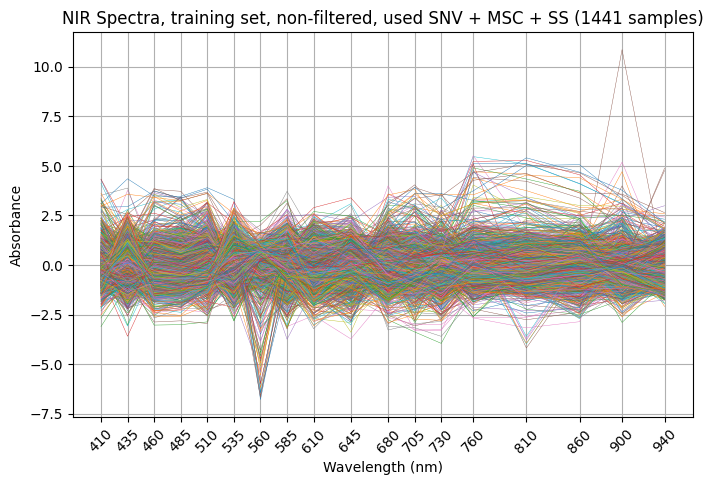

In [47]:
snv_msc_ss = StandardScaler()
X_train_snv_msc_ss = snv_msc_ss.fit_transform(X_train_snv_msc)
X_test_snv_msc_ss = snv_msc_ss.transform(X_test_snv_msc)

spectra_plot(pd.DataFrame(X_train_snv_msc_ss, columns=wavelengths),
             'NIR Spectra, training set, non-filtered, used SNV + MSC + SS')

In [48]:
pbounds = {
    'log_C': (0, 3.0),
    'log_gamma': (-3.0, 1.0),
    'epsilon': (0.001, 1.0)
}

def objective_wrapper (log_C, log_gamma, epsilon):
  return svr_val_evaluate(X_train_snv_msc_ss, X_test_snv_msc_ss, y_train, y_test, log_C, log_gamma, epsilon)

optimizer = BayesianOptimization(f=objective_wrapper, pbounds=pbounds,
                                 random_state=42, verbose=2)
optimizer.maximize(init_points=5, n_iter=200)

print(f"Best params: {optimizer.max['params']}")
p, target = optimizer.max['params'], optimizer.max['target']
svr_training.loc[len(svr_training)] = ['SVR + SNV + MSC + SS', target, 10**p['log_C'], 10**p['log_gamma'], p['epsilon']]

|   iter    |  target   |   log_C   | log_gamma |  epsilon  |
-------------------------------------------------------------
| 1         | -3.908369 | 1.1236203 | 0.8028572 | 0.7322619 |
| 2         | -2.456902 | 1.7959754 | -2.375925 | 0.1568385 |
| 3         | -3.677468 | 0.1742508 | 0.4647045 | 0.6015138 |
| 4         | -2.751412 | 2.1242177 | -2.917662 | 0.9699399 |
| 5         | -2.144541 | 2.4973279 | -2.150643 | 0.1826431 |
| 6         | -3.129834 | 3.0       | -0.924933 | 0.001     |
| 7         | -2.547188 | 3.0       | -3.0      | 0.001     |
| 8         | -3.486860 | 0.0       | -3.0      | 0.001     |
| 9         | -2.321433 | 3.0       | -2.012898 | 1.0       |
| 10        | -2.016440 | 1.9859783 | -1.605390 | 1.0       |
| 11        | -2.092100 | 0.9692785 | -1.512685 | 1.0       |
| 12        | -1.912933 | 1.3624358 | -1.283549 | 0.0456964 |
| 13        | -2.093658 | 0.3003850 | -1.226903 | 0.001     |
| 14        | -2.403468 | 0.0       | -1.334047 | 1.0       |
| 15    

In [49]:
svr_training

,Method,Validation -MSE,Best_C,Best_gamma,Best_epsilon
0,SVR + raw data,-1.698280,673.854792,10.000000,0.849290
1,SVR + SS,-1.604395,26.216295,0.152266,0.367627
2,SVR + SNV + MSC + SS,-1.715924,9.452708,0.193029,0.212662


--- SVR + SNV + MSC + SS, (C, gamma, epsilon) = (9.45, 0.19, 0.21) ---
Training RMSE: 0.5454
Testing RMSE: 1.3099
Training R²: 0.9263
Testing R²: 0.5745


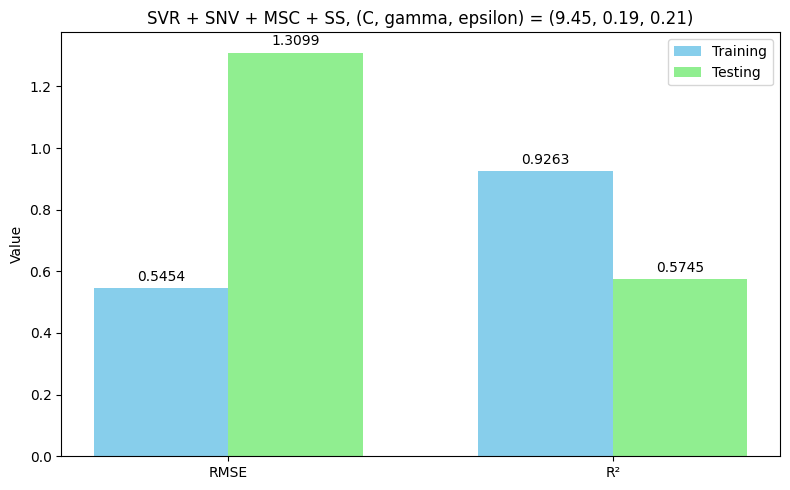

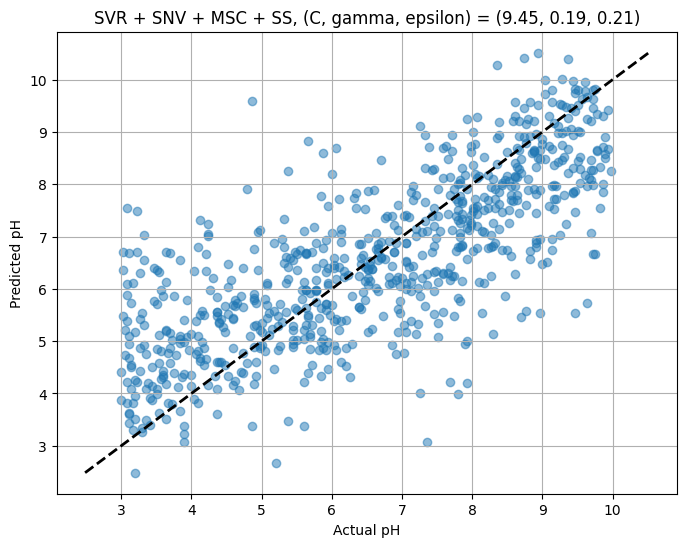

In [50]:
C, gamma, epsilon = svr_training.loc[svr_training['Method'] == "SVR + SNV + MSC + SS"
                                    , ['Best_C', 'Best_gamma', 'Best_epsilon']].iloc[-1]
svr_snv_msc_ss = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(X_train_snv_msc_ss, y_train)
metrics_calculation(svr_snv_msc_ss, X_train_snv_msc_ss, y_train, X_test_snv_msc_ss, y_test,
                    f'SVR + SNV + MSC + SS, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',
                    f'SVR + SNV + MSC + SS, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',False, True)

##### **SVR + MRMR**

#### **SVR + NN + RF + SHAP**

In [ ]:
model_nn = Sequential([
    Dense(32, activation='relu', input_shape=(18,)),
    Dense(16, activation='relu'),
    Dense(1, activation='linear')
])
model_nn.compile(optimizer='adam', loss='mse', metrics=['mae'])
early_stop=EarlyStopping(
    monitor='val_loss',
    patience=20,
    restore_best_weights=True
)
history = model_nn.fit(
    X_train_snv_msc_ss, y_train,
    validation_data = (X_test_snv_msc_ss, y_test),
    epochs=300,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/300
91/91 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 31.6376 - mae: 5.1076 - val_loss: 15.1063 - val_mae: 3.2535
Epoch 2/300
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 7.9959 - mae: 2.2578 - val_loss: 6.7140 - val_mae: 2.0752
Epoch 3/300
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5.4512 - mae: 1.8731 - val_loss: 5.4585 - val_mae: 1.8821
Epoch 4/300
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 4.5504 - mae: 1.7431 - val_loss: 4.6651 - val_mae: 1.7453
Epoch 5/300
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 4.0199 - mae: 1.6528 - val_loss: 4.0909 - val_mae: 1.6359
Epoch 6/300
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 3.5860 - mae: 1.5625 - val_loss: 3.7813 - val_mae: 1.5874
Epoch 7/300
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 3.3219 - mae: 1.5012 - val_loss: 3.4617 - val_mae: 1.5133
Epoch 8/300
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 3.0606 - mae: 1.4413 - val_loss: 3.2066 - val_mae: 1.4565
Epoch 9/300
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.8

In [ ]:
r2_nn = r2_score(y_test, model_nn.predict(X_test_snv_msc_ss))

24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


In [ ]:
model_svr = svr_snv_msc_ss
r2_svr = r2_score(y_test, model_svr.predict(X_test_snv_msc_ss))

In [ ]:
model_rf = RandomForestRegressor()
model_rf.fit(X_train_snv_msc_ss, y_train)
r2_rf = r2_score(y_test, model_rf.predict(X_test_snv_msc_ss))

In [ ]:
X_summary = shap.kmeans(X_train_snv_msc_ss, 50)
explainer_svr = shap.KernelExplainer(model_svr.predict, X_summary)
shap_svr = explainer_svr.shap_values(X_test_snv_msc_ss)

explainer_nn = shap.DeepExplainer(model_nn, X_train_snv_msc_ss)
shap_nn = explainer_nn.shap_values(X_test_snv_msc_ss)

  0%|          | 0/744 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/shap/explainers/_deep/deep_tf.py:94: UserWarning: Your TensorFlow version is newer than 2.4.0 and so graph support has been removed in eager mode and some static graphs may not be supported. See PR #1483 for discussion.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor
Received: inputs=['Tensor(shape=(1441, 18))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor
Received: inputs=['Tensor(shape=(2882, 18))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor
Received: inputs=['Tensor(shape=(744, 18))']
  warnings.warn(

NameError: name 'explainer' is not defined

In [ ]:
explainer_rf = shap.TreeExplainer(model_rf)
shap_rf = explainer_rf.shap_values(X_test_snv_msc_ss)

In [ ]:
print(shap_svr.shape)
print(shap_nn.shape)
print(shap_rf.shape)

(744, 18)
(744, 18, 1)
(744, 18)


In [ ]:
shap_nn = np.squeeze(shap_nn)
fused_shap = r2_nn * shap_nn + r2_svr * shap_svr + r2_rf * shap_rf

In [ ]:
feature_importance = np.abs(fused_shap).mean(axis=0)
feature_importance

array([0.21543298, 0.33976058, 0.13926497, 0.96437852, 0.61342571,
       0.1417015 , 0.28402744, 0.75260696, 0.18215806, 0.47781861,
       0.19116162, 0.3216907 , 0.15155596, 0.14003407, 0.15998574,
       0.18191111, 0.24988019, 0.26951485])

In [ ]:
threshold = np.percentile(feature_importance, 20) # Define cutoff for bottom 20%
selected_indices = np.where(feature_importance > threshold)[0]
selected_features = wavelengths[selected_indices]
selected_features

array([410, 435, 485, 510, 560, 585, 610, 645, 680, 705, 810, 860, 900,
       940], dtype=object)

In [ ]:
selected_indices

array([ 0,  1,  3,  4,  6,  7,  8,  9, 10, 11, 14, 15, 16, 17])

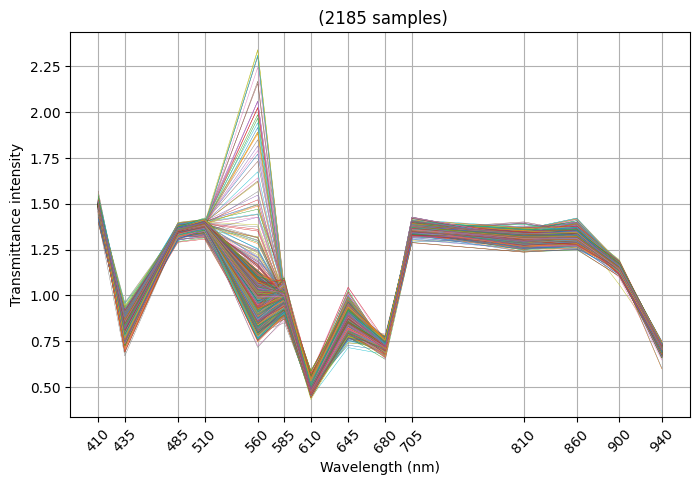

In [ ]:
spectra_plot(df_normalized[selected_features])

##### **Retrain**

In [ ]:
X_train_snv_msc_ss_drop = X_train_snv_msc_ss[:,selected_indices]
X_test_snv_msc_ss_drop = X_test_snv_msc_ss[:,selected_indices]

In [ ]:
X_train_snv_msc_ss_drop.shape

(1441, 14)

In [ ]:
pbounds = {
    'log_C': (0, 3.0),
    'log_gamma': (-3.0, 1.0),
    'epsilon': (0.001, 1.0)
}

def objective_wrapper (log_C, log_gamma, epsilon):
  return svr_val_evaluate(X_train_snv_msc_ss_drop, X_test_snv_msc_ss_drop, y_train, y_test, log_C, log_gamma, epsilon)

optimizer = BayesianOptimization(f=objective_wrapper, pbounds=pbounds,
                                 random_state=42, verbose=2)
optimizer.maximize(init_points=5, n_iter=200)

print(f"Best params: {optimizer.max['params']}")
p, target = optimizer.max['params'], optimizer.max['target']
svr_training.loc[len(svr_training)] = ['SVR + SNV + MSC + SS', target, 10**p['log_C'], 10**p['log_gamma'], p['epsilon']]

|   iter    |  target   |   log_C   | log_gamma |  epsilon  |
-------------------------------------------------------------
| 1         | -3.797853 | 1.1236203 | 0.8028572 | 0.7322619 |
| 2         | -2.610176 | 1.7959754 | -2.375925 | 0.1568385 |
| 3         | -3.292716 | 0.1742508 | 0.4647045 | 0.6015138 |
| 4         | -2.778514 | 2.1242177 | -2.917662 | 0.9699399 |
| 5         | -2.290183 | 2.4973279 | -2.150643 | 0.1826431 |
| 6         | -2.898453 | 3.0       | -1.335536 | 1.0       |
| 7         | -2.709894 | 3.0       | -3.0      | 0.001     |
| 8         | -2.070810 | 2.2573148 | -1.315676 | 0.001     |
| 9         | -2.436764 | 3.0       | -0.579294 | 0.001     |
| 10        | -3.470323 | 0.0       | -3.0      | 1.0       |
| 11        | -2.661743 | 3.0       | -1.549100 | 0.001     |
| 12        | -1.842655 | 1.4778812 | -1.065429 | 0.001     |
| 13        | -1.968448 | 1.5296705 | -1.199043 | 0.7484861 |
| 14        | -2.082495 | 0.4724549 | -1.220402 | 0.001     |
| 15    

In [ ]:
svr_training

,Method,Validation -MSE,Best_C,Best_gamma,Best_epsilon
0,SVR + SNV + MSC + SS,-1.576166,8.232540,0.221165,0.116050
1,SVR + SNV + MSC + SS,-1.607047,7.323884,0.401008,0.147328


--- SVR + SNV + MSC + SS, dropped, (C, gamma, epsilon) = (7.32, 0.40, 0.15) ---
Training RMSE: 0.4325
Testing RMSE: 1.2677
Training R²: 0.9536
Testing R²: 0.6015


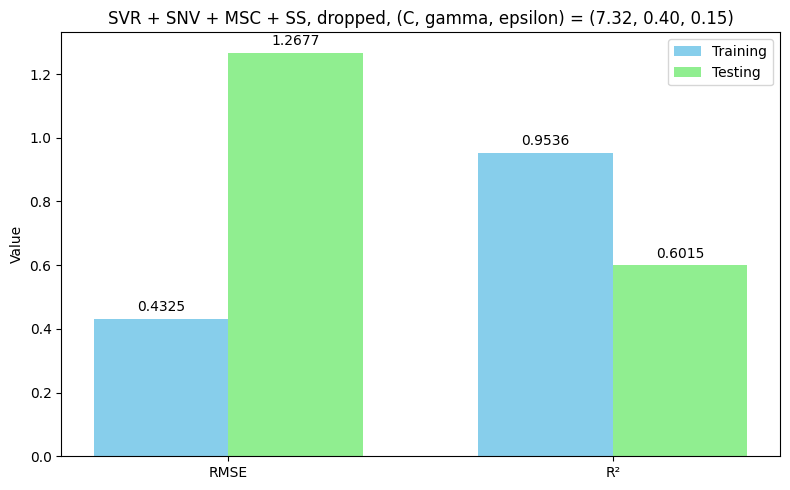

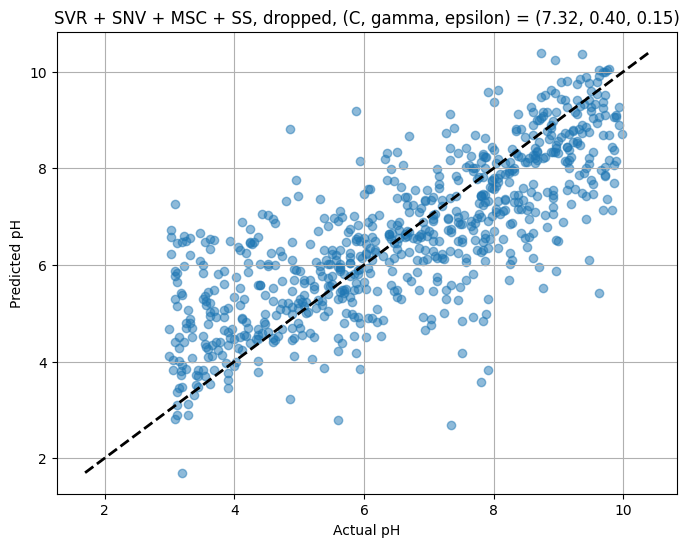

In [ ]:
C, gamma, epsilon = svr_training.loc[svr_training['Method'] == "SVR + SNV + MSC + SS"
                                    , ['Best_C', 'Best_gamma', 'Best_epsilon']].iloc[-1]
svr_snv_msc_ss = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(X_train_snv_msc_ss_drop, y_train)
metrics_calculation(svr_snv_msc_ss, X_train_snv_msc_ss_drop, y_train, X_test_snv_msc_ss_drop, y_test,
                    f'SVR + SNV + MSC + SS, dropped, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',
                    f'SVR + SNV + MSC + SS, dropped, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',0, 0)

In [ ]:
r2_nn

0.5630637265056588

In [ ]:
model_nn = Sequential([
    Dense(32, activation='relu', input_shape=(14,)),
    Dense(16, activation='relu'),
    Dense(1, activation='linear')
])
model_nn.compile(optimizer='adam', loss='mse', metrics=['mae'])
history = model_nn.fit(
    X_train_snv_msc_ss_drop, y_train,
    validation_data = (X_test_snv_msc_ss_drop, y_test),
    epochs=300,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/300
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 42.7039 - mae: 6.1724 - val_loss: 27.9718 - val_mae: 4.8514
Epoch 2/300
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 13.8426 - mae: 3.0948 - val_loss: 8.4018 - val_mae: 2.2916
Epoch 3/300
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 6.6515 - mae: 2.0575 - val_loss: 6.3697 - val_mae: 2.0199
Epoch 4/300
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5.3041 - mae: 1.8649 - val_loss: 5.3396 - val_mae: 1.8664
Epoch 5/300
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 4.5557 - mae: 1.7383 - val_loss: 4.7165 - val_mae: 1.7583
Epoch 6/300
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 4.0749 - mae: 1.6482 - val_loss: 4.2724 - val_mae: 1.6644
Epoch 7/300
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 3.7688 - mae: 1.5879 - val_loss: 3.9769 - val_mae: 1.6035
Epoch 8/300
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 3.5224 - mae: 1.5301 - val_loss: 3.7715 - val_mae: 1.5760
Epoch 9/300
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 3.

In [ ]:
r2_score(y_test, model_nn.predict(X_test_snv_msc_ss_drop))

#### **Cubist**

In [ ]:
# Giữ outliers

cub = Cubist(
    n_rules=500,
    n_committees=1,
    neighbors=5,
    unbiased=True,
    auto=False,
    extrapolation=0.05,
    sample=None,
    cv=None,
    random_state=42,
    target_label='outcome',
    verbose=0
)

cub.fit(X_train_snv, y_train)
print("Đã train xong")

In [ ]:
metrics_calculation(cub,
                    X_train_snv, y_train,
                    X_test_snv, y_test,
                    'SNV + Cubist, non-filtered',
                    'SNV + Cubist, non-filtered, testing set', 1, 1)

In [ ]:
calculate_and_plot_shap(cub, X_train_snv, X_test_snv,
                        wavelengths)

In [ ]:
# Bỏ outliers

cub_filtered = Cubist(
    n_rules=500,
    n_committees=1,
    neighbors=5,
    unbiased=True,
    auto=False,
    extrapolation=0.05,
    sample=None,
    cv=None,
    random_state=42,
    target_label='outcome',
    verbose=0
)

cub_filtered.fit(X_train_filtered_msc, y_train_filtered)
print("Đã train xong")

In [ ]:
metrics_calculation(cub_filtered,
                    X_train_filtered_msc, y_train_filtered,
                    X_test_filtered_msc, y_test_filtered,
                    'MSC + Cubist, used filter',
                    'MSC + Cubist, used filter, testing set')

In [ ]:
# Tính SHAP value

calculate_and_plot_shap(cub_filtered, X_train_filtered_snv, X_test_filtered_snv, wavelengths)